![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)

# UAV-Based High-Throughput Phenotyping of Maize Nitrogen Response

Replicate, end to end and in Python, the study of Rodene et al. (2021): 233 maize inbred lines of the
Buckler-Goodman association panel grown at the Havelock farm (Lincoln, Nebraska) in 2019 under
nitrogen-fertilized (+N) and nitrogen-limited (-N) conditions, flown 12 times with an RGB UAV. We go from raw
UAV pixels to foliage masks and greenness indices, from plot-level image traits to the nitrogen response of each
genotype, from image traits to ground-truth leaf nitrogen, leaf area and kernel weight, and from time-series traits
to heritability, genome-wide association (GWAS) and genomic prediction.

## Overview

**High-throughput phenotyping (HTP).** Genotyping a breeding or diversity panel now costs little, while measuring
traits on thousands of field plots by hand is slow, destructive and done only once or twice a season. A UAV
carrying a consumer RGB camera can photograph every plot of a trial in minutes, as often as the weather allows. Each
flight becomes a *snapshot* of canopy size and greenness for every genotype, and a season of flights becomes a
*time series* that captures growth, nitrogen (N) stress and senescence. These image-extracted traits can then be
used like any other phenotype: tested for treatment effects, correlated with physiology and yield, and mapped to
the genome.

**The case study.** In 2019, 233 inbred lines of the maize association panel plus a hybrid check were
planted in four quadrants. Two quadrants (NE, SW) received standard inorganic N before planting (+N) and two (NW, SE)
received none (-N). Each quadrant holds one replicate: six ranges of 42 two-row subplots (5 ft × 20 ft), 252
subplots per quadrant, in an incomplete split-plot block design with 27 to 37 hybrid checks per quadrant. A DJI
Phantom 4 Pro (20 MP RGB, 5472 × 3648 px) flew 12 times between July 6 and September 5 at 22 to 27 m.

**The image pipeline of the paper** (Figure 1B):

| Step | What happens | Tool in the paper | What we do here |
|---|---|---|---|
| Orthomosaic | Frames of a flight are stitched into one field map | Pix4D, Plot Phenix | Shown as a preview image |
| Plot clipping | Each two-row subplot is cut from the *original* frames; the most nadir copy is the **reference replicate** | Plot Phenix | Reference replicate tables are provided |
| Foliage mask | Soil, shadow and debris pixels are removed with a binary mask | MATLAB (`vi_script.m`) | Re-implemented on raw frames with NumPy and GeoLattice |
| Greenness | Eight RGB vegetation indices (VIs) averaged over foliage pixels | MATLAB | Re-implemented; plot tables reused for all 12 dates |
| Canopy coverage | Percentage of plot pixels kept as foliage | MATLAB | Re-implemented; plot tables reused |

**Why only RGB?** NIR and red-edge indices (NDVI, NDRE) are more robust, but multispectral sensors cost much more.
RGB indices exploit the fact that healthy leaves reflect more green than red or blue. Their weakness is that the
camera adjusts exposure and white balance per frame, so the same canopy can look brighter or more saturated on
another flight. The paper therefore divides each VI by the frame's **light value** (an exposure measure from the
EXIF tags) and the plot's mean **colour saturation**.

**The eight VIs** (R, G, B are 8-bit channel values; r, g, b are chromatic coordinates, e.g. r = R/(R+G+B)):

| Index | Formula | Idea |
|---|---|---|
| ExG (Excess Green) | 2g − r − b | Green excess relative to red and blue |
| RGBVI | (G² − R·B) / (G² + R·B) | Green squared against red times blue |
| NGRDI | (G − R) / (G + R) | Normalised green-red difference |
| GLI (Green Leaf Index) | (2G − R − B) / (2G + R + B) | Bounded form of ExG |
| MGRVI | (G² − R²) / (G² + R²) | Squared green-red contrast |
| VARI | (G − R) / (G + R − B) | Green-red contrast corrected for atmosphere |
| VEG | G / (R^0.667 · B^0.333) | Green against a weighted red-blue mean |
| Woebbecke | (G − B) / \|R − G\| | Ratio of green-blue to red-green differences |

**From traits to genes.** A trait measured on replicated plots of many lines can be split into genetic and
environmental variance; the share that is genetic (broad-sense **heritability**, H²) tells us whether a trait is
worth mapping. **GWAS** tests every SNP for association with the trait in a mixed linear model that includes
principal components (population structure) and a kinship matrix (relatedness), so that only genuine marker-trait
associations stand out. **Genomic prediction** (GBLUP) uses all markers together to predict the genetic value of
untested lines. The paper ran GWAS in GEMMA on about 21 million HapMap3 SNPs and reported 29 genomic regions found at
three or more time points, including a canopy-coverage peak on chromosome 1 (208.8 to 209.1 Mb) next to
*Zm00001d031997*, a homolog of the Arabidopsis photosystem II assembly gene *HCF244*.

**What is real and what is simulated.** Everything in the main analysis is real: UAV pixels, plot traits, field
data, the published GWAS regions and the HapMap3 genotypes of the 282 association panel (Bukowski et al. 2018),
which we download, filter and analyse with PLINK 2, GEMMA and a fast EMMAX implementation. One short module teaches
the GWAS and genomic-prediction *methods* on simulated SNPs with known QTL first, so that the behaviour of the
estimators can be checked against the truth; it is labelled **[SIMULATED]** and must not be read as biology.

### Applications

* Screening diversity panels and breeding nurseries for N-use efficiency and stay-green.
* Replacing visual scores and destructive leaf sampling with repeatable image traits.
* Time-resolved GWAS that reveals loci acting at specific developmental stages.
* Phenomic selection: predicting physiology or yield from cheap image traits.

## UAV phenotyping with GeoLattice

`geolattice.rsense.uav` covers the camera side of this workflow: `read_frame` reads a DJI JPEG as a `(band, y, x)`
DataArray scaled to 0 to 1, `vegetation_indices` computes RGB indices (ExG, VARI, GLI, NGRDI, ...),
`exg_plant_mask` and `canopy_cover` threshold an index into a foliage mask with Otsu's method, `exposure_stats`
reports brightness and clipping, and `fit_logistic` fits growth or senescence curves through dated traits. The
paper's exact VI formulas, the fixed ExG threshold of 131 and the HSL saturation are written out below as small NumPy
functions so that each step of the MATLAB pipeline is visible; we check them against the GeoLattice functions where both
exist.

### Learning objectives

By the end of this notebook you will be able to:

* Build a reproducible pipeline from raw UAV pixels to plot traits, field traits and genetic analysis.
* Separate foliage from soil with ExG thresholds (fixed and Otsu) and compute canopy coverage and eight RGB VIs.
* Quantify and correct camera exposure and saturation effects with EXIF light values and HSL saturation.
* Test nitrogen effects on the hybrid checks and on the +N/−N ratio of 225 genotypes across 12 dates.
* Correlate VIs with leaf nitrogen, leaf area and 20-kernel weight and find the best index and date.
* Derive season traits (maximum, timing, area under the curve, senescence rate) from the time series.
* Estimate broad-sense heritability with and without field-trend (range) adjustment.
* Summarise published GWAS regions by recurrence across dates and traits.
* Run a mixed-model GWAS (kinship + PCs), call peaks and check genomic inflation, first on simulated SNPs with known
  QTL, then on 14 million real HapMap3 SNPs for canopy coverage and the eight VIs.
* Predict image and field traits from real genomic relationships (GBLUP) and judge accuracy against heritability,
  N levels and population structure.

### Data

All files are in `Data/08_remote_sensing/08_11_Capstones/maize_uav_htp` (see its `README.md`). They come from the
authors' repository `UAV-based_HTP` (Yang Lab, University of Nebraska-Lincoln, GPLv3).

| Folder | Content |
|---|---|
| `uav_images/` | Two raw DJI frames of the Havelock field (2018, about 11 m AGL) and an orthomosaic preview |
| `plot_traits/` | Reference-replicate plot tables for 2019: canopy coverage and VIs for four pixel filters, 12 dates, with light value and saturation; published N-response statistics; supplementary tables S1 and S2 |
| `field/` | Field book (plot, genotype, treatment, rep), 20-kernel weight and cob traits, leaf area, chlorophyll and leaf nutrients |
| `gwas/` | Table S3 of the paper: 345 GWAS candidate regions (trait, treatment, date, position, lead SNP p-value) |
| `genotypes/` | Pipeline scripts for the HapMap3 282-panel genotypes (download and filter, GEMMA, EMMAX), the sample mapping, filtered PLINK files, kinship, PCs and reduced GWAS results |

### Contents

* Setup and data inventory
* Study design and field layout
* Pixel-level pipeline on raw UAV frames
* Choosing the foliage filter
* Light, saturation and VI normalisation
* Canopy coverage response to nitrogen
* Vegetation index response to nitrogen
* VIs as predictors of leaf and yield traits
* Season traits from the time series
* Field trends and heritability
* Published GWAS regions
* GWAS and genomic prediction methods [SIMULATED]
* GWAS on real HapMap3 genotypes
* Genomic prediction with real genotypes
* Phenomic prediction of leaf nitrogen
* Export, summary and exercises


geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`, plus `statsmodels` and `scikit-learn`.
See "Installation options" in the GeoLattice README.

**How to use it.** Run the cells in order (Restart and Run All should finish in a few minutes). Cells marked
**[CHECK]** assert that an intermediate result is sane; exercises at the end are marked **[EXERCISE]**.

## Setup and data inventory

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README. It also uses `seaborn`, `statsmodels`, which no GeoLattice option installs: `pip install seaborn statsmodels`.

In [1]:
import json, hashlib, sys, platform, warnings                       # standard library helpers
from pathlib import Path                                             # portable paths
warnings.filterwarnings("ignore")                                    # keep the teaching output readable

import numpy as np                                                   # arrays
import pandas as pd                                                  # tables
import matplotlib.pyplot as plt                                      # plotting
import seaborn as sns                                                # statistical plots
from PIL import Image                                                # EXIF tags of the DJI frames
from scipy import stats                                              # t-tests, correlations
from scipy.stats import chi2                                         # genomic inflation factor
from skimage.filters import threshold_otsu                           # Otsu threshold (as MATLAB graythresh)
import statsmodels.formula.api as smf                                # linear models with formulas
from statsmodels.stats.multitest import multipletests                # FDR correction
from sklearn.decomposition import PCA                                # population structure
from sklearn.linear_model import Ridge, RidgeCV                      # ridge regression (rrBLUP)
from sklearn.ensemble import RandomForestRegressor                   # non-linear phenomic model
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict  # cross-validation schemes
from sklearn.pipeline import make_pipeline                           # scaler + model in one estimator
from sklearn.preprocessing import StandardScaler                     # standardise predictors

import geolattice.rsense as rs                                            # GeoLattice remote sensing (rs.uav)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})  # plotting defaults
sns.set_theme(style="whitegrid", context="notebook")                 # seaborn theme
SEED = 42                                                            # one seed for simulation and CV
rng = np.random.default_rng(SEED)                                    # random generator used throughout

In [2]:
DATA = Path("../../../../Data/08_remote_sensing/08_11_Capstones/maize_uav_htp")  # capstone data folder
OUT = DATA / "outputs"                                               # figures and tables written here
for sub in ("figures", "tables"):                                    # create output sub-folders
    (OUT / sub).mkdir(parents=True, exist_ok=True)

FILES = {                                                            # every input used by the notebook
    "frame_soil": DATA / "uav_images/DJI_0004.JPG",                  # raw frame with soil, weeds and plots
    "frame_plots": DATA / "uav_images/DJI_0009.JPG",                 # raw frame over young two-row plots
    "ortho": DATA / "uav_images/havelock_2018.jpg",                  # orthomosaic preview
    "vi_plots": DATA / "plot_traits/VI_average_fb2019_n46364_ref.csv",  # plot VIs, 4 filters, 12 dates
    "cc_geno": DATA / "plot_traits/geno_ref.csv",                    # canopy coverage of genotype plots
    "cc_check": DATA / "plot_traits/check_ref.csv",                  # canopy coverage of hybrid checks
    "pub_cc_check": DATA / "plot_traits/CC_pval_checks_ExG131.csv",  # published check statistics
    "pub_cc_geno": DATA / "plot_traits/CC_pval_genotype_ExG131.csv", # published genotype statistics
    "field_book": DATA / "field/CRRI_2019_Field_Book_final.csv",     # plot to genotype map
    "yield": DATA / "field/2019_yield_traits.csv",                   # 20-kernel weight and cob traits
    "leaf": DATA / "field/leaf_traits_spectra_2019.csv",             # leaf area, chlorophyll, nutrients
    "gwas": DATA / "gwas/Table_S3_GWAS_regions.csv",                 # published GWAS regions
}

def md5(path, chunk=1 << 20):
    """Short MD5 fingerprint of a file, to record exactly which data were analysed."""
    h = hashlib.md5()                                                # running hash
    with open(path, "rb") as f:                                      # read in binary chunks
        for block in iter(lambda: f.read(chunk), b""):               # until end of file
            h.update(block)                                          # add chunk to the hash
    return h.hexdigest()[:12]                                        # 12 characters are enough here

inventory = pd.DataFrame([{"item": k, "file": p.name, "exists": p.exists(),        # one row per input
                           "size_mb": round(p.stat().st_size / 1e6, 2), "md5": md5(p)}
                          for k, p in FILES.items()])
assert inventory.exists.all(), "Missing input files"                 # [CHECK] all inputs present
provenance = {"python": sys.version.split()[0], "platform": platform.platform(),  # software record
              "numpy": np.__version__, "pandas": pd.__version__}
(OUT / "tables/provenance.json").write_text(json.dumps(provenance, indent=2))  # save provenance
inventory

,item,file,exists,size_mb,md5
0,frame_soil,DJI_0004.JPG,True,8.20,06468a5e3abb
1,frame_plots,DJI_0009.JPG,True,8.22,7a710e411711
2,ortho,havelock_2018.jpg,True,0.35,f235363f6591
3,vi_plots,VI_average_fb2019_n46364_ref.csv,True,17.75,64f53a209c48
4,cc_geno,geno_ref.csv,True,11.97,9f1025672f52
5,cc_check,check_ref.csv,True,1.75,e29ca4d05151
6,pub_cc_check,CC_pval_checks_ExG131.csv,True,0.00,43d7e4057388
7,pub_cc_geno,CC_pval_genotype_ExG131.csv,True,0.00,492969bcef56
8,field_book,CRRI_2019_Field_Book_final.csv,True,0.07,d928f45c7f21
9,yield,2019_yield_traits.csv,True,0.09,5b55f06cc942


In [3]:
DATES = ["July6", "Aug12", "Aug14", "Aug16", "Aug20", "Aug22", "Aug23", "Aug26", "Aug30",
         "Sept1", "Sept3", "Sept5"]                                  # the 12 flights in time order
DATE_TS = pd.to_datetime(["2019-07-06", "2019-08-12", "2019-08-14", "2019-08-16", "2019-08-20",
                          "2019-08-22", "2019-08-23", "2019-08-26", "2019-08-30", "2019-09-01",
                          "2019-09-03", "2019-09-05"])               # calendar dates of the flights
DOY = dict(zip(DATES, DATE_TS.dayofyear))                            # flight label to day of year
LABEL = dict(zip(DATES, DATE_TS.strftime("%b %-d")))                 # flight label to "Aug 12" style
VI8 = {"ExG2": "ExG", "RGB": "RGBVI", "NGR": "NGRDI", "GLI": "GLI", "MGR": "MGRVI",
       "VARI": "VARI", "VEG": "VEG", "Woebbecke..abs.": "Woebbecke"}  # table column to paper name
TRT_COL = {"Nitrogen": "#E69F00", "No Nitrogen": "#56B4E9"}          # +N orange, -N blue (paper colours)
TRT_LAB = {"Nitrogen": "+N", "No Nitrogen": "-N"}                    # short treatment labels

## Study design and field layout

The field book links each **Row** (the plot id: 1xxx = NE, 2xxx = NW, 3xxx = SE, 4xxx = SW quadrant) to a genotype,
treatment and replicate. Plot names in the image tables also carry the quadrant, the two-row column (`row_1` to
`row_42`) and the range (`range_1` to `range_6`), which gives us field coordinates for trend analysis later.

Two points of design matter for every analysis below:

* **Treatment and replicate are confounded with quadrant.** Each quadrant is one treatment × rep. Any soil or
  drainage difference between quadrants is mixed into the N effect, which is why the hybrid check, repeated 27 to 37
  times per quadrant, is so valuable: it shows the N effect on one genetically uniform reference.
* **Plot-level, not pixel-level, inference.** A plot holds thousands of pixels, but the experimental unit is the
  plot. Pixel counts make plot means precise; they do not add replication.

In [4]:
fb = pd.read_csv(FILES["field_book"])                                # field book, one row per plot
fb["quadrant"] = fb.Row.astype(str).str[0].map({"1": "NE", "2": "NW", "3": "SE", "4": "SW"})  # from plot id
design = (fb.groupby(["quadrant", "Treatment", "Rep"])               # plots per quadrant
            .agg(plots=("Row", "size"), genotypes=("Genotype", "nunique"),
                 checks=("Genotype", lambda g: (g == "Check").sum())).reset_index())
print(f"{len(fb)} plots, {fb.Genotype.nunique()} entries "
      f"({fb.loc[fb.Genotype != 'Check', 'Genotype'].nunique()} inbreds + hybrid check)")
design

2016 plots, 234 entries (233 inbreds + hybrid check)


,quadrant,Treatment,Rep,plots,genotypes,checks
0,NE,Nitrogen,1,504,226,54
1,NW,No Nitrogen,1,504,223,60
2,SE,No Nitrogen,2,504,217,72
3,SW,Nitrogen,2,504,216,74


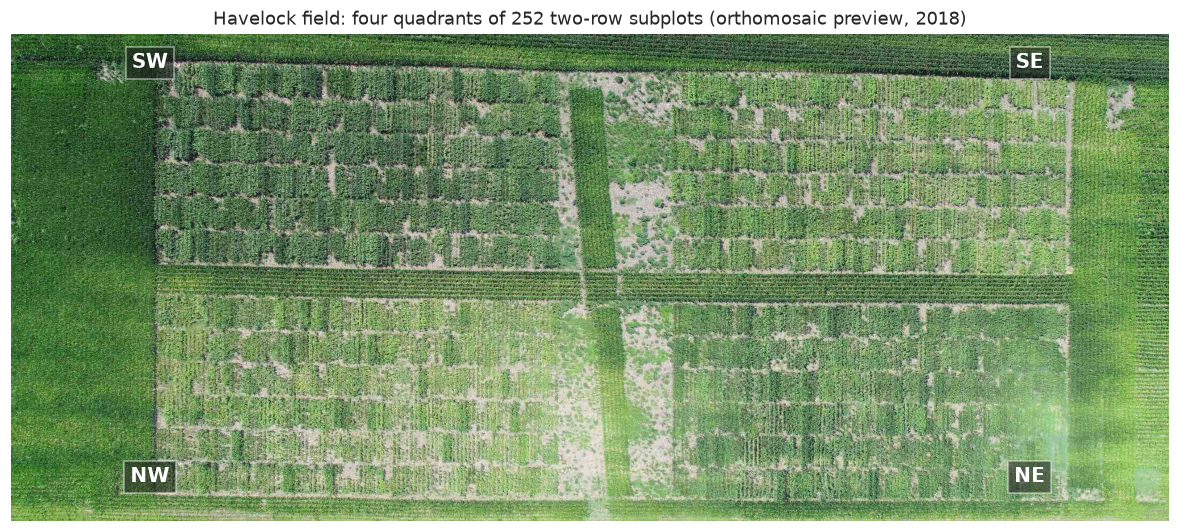

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))                              # orthomosaic preview
ax.imshow(Image.open(FILES["ortho"]))                                # 2018 orthomosaic of the same field
for txt, (x, y) in {"NW": (0.12, 0.08), "NE": (0.88, 0.08), "SW": (0.12, 0.93), "SE": (0.88, 0.93)}.items():
    ax.text(x, y, txt, transform=ax.transAxes, fontsize=13, weight="bold", color="w",  # quadrant labels
            ha="center", bbox=dict(fc="k", alpha=0.5))
ax.set_title("Havelock field: four quadrants of 252 two-row subplots (orthomosaic preview, 2018)")
ax.axis("off"); plt.tight_layout(); plt.show()

**[CHECK]** 2,016 plots, four quadrants of 504 plots (252 two-row subplots, each two field rows), 234 entries.

In [6]:
assert len(fb) == 2016 and fb.groupby("quadrant").size().eq(504).all()   # [CHECK] design is complete

## Pixel-level pipeline on raw UAV frames

Here we rebuild the MATLAB script `vi_script.m` of the authors on two raw DJI frames from the same field. For each
pixel it:

1. scales R, G, B to 0 to 1 and computes **ExG = 2G − R − B** (range −2 to 2);
2. builds four candidate foliage masks:
   * **ExG 131**: rescale ExG to 0 to 255 with (ExG + 2)/4 × 255 and keep pixels ≥ 131 (ExG ≥ 0.055);
   * **Otsu pre**: Otsu's threshold on raw ExG;
   * **Otsu post**: Otsu's threshold on the 0 to 255 rescaled ExG;
   * **Custom**: a hand-built RGB lookup cube (not distributed, so skipped here);
3. averages the eight VIs over the foliage pixels and reports **canopy coverage** = foliage pixels / all pixels;
4. records the HSL **saturation** of the foliage pixels (Windows 0 to 240 scale, as in MATLAB) and the frame's
   EXIF **light value**.

The EXIF light value is the exposure value normalised to ISO 100:
LV = log₂(N²/t) + log₂(100/ISO), with N the f-number and t the exposure time. A brighter scene forces a shorter
exposure or smaller aperture and therefore a higher LV.

In [7]:
def light_value(path):
    """EXIF light value LV = log2(N^2 / t) + log2(100 / ISO) of a camera frame."""
    exif = Image.open(path).getexif().get_ifd(0x8769)                # Exif sub-IFD holds exposure tags
    t, n, iso = float(exif[33434]), float(exif[33437]), float(exif[34855])  # ExposureTime, FNumber, ISO
    return np.log2(n ** 2 / t) + np.log2(100 / iso)                  # exposure value at ISO 100

def hsl_saturation(R, G, B):
    """HSL saturation on the Windows 0-240 scale, as computed per pixel in vi_script.m."""
    cmax, cmin = np.maximum(np.maximum(R, G), B), np.minimum(np.minimum(R, G), B)  # channel extremes
    L = ((cmax + cmin) * 240 + 255) / (2 * 255)                      # lightness on the 0-240 scale
    with np.errstate(divide="ignore", invalid="ignore"):             # grey pixels give 0/0
        s_lo = ((cmax - cmin) * 240 + (cmax + cmin) / 2) / (cmax + cmin)            # dark half
        s_hi = ((cmax - cmin) * 240 + (510 - cmax - cmin) / 2) / (510 - cmax - cmin)  # bright half
    S = np.where(L <= 120, s_lo, s_hi)                               # choose by lightness
    return np.where(cmax == cmin, 0.0, S)                            # grey pixels have no saturation

def paper_indices(R, G, B):
    """The eight VIs of Table 1 (plus raw ExG) from 8-bit R, G, B arrays."""
    Rs, Gs, Bs = R / 255, G / 255, B / 255                           # 0-1 channels
    tot = Rs + Gs + Bs                                               # brightness for chromatic coordinates
    with np.errstate(divide="ignore", invalid="ignore"):             # black pixels and R == G give inf/nan
        r, g, b = Rs / tot, Gs / tot, Bs / tot                       # chromatic coordinates
        return {
            "ExG_raw": 2 * Gs - Rs - Bs,                             # excess green on 0-1 channels
            "ExG": 2 * g - r - b,                                    # excess green on chromatic coords (ExG2)
            "RGBVI": (G**2 - R * B) / (G**2 + R * B),                # red-green-blue VI
            "NGRDI": (G - R) / (G + R),                              # normalised green-red difference
            "GLI": (2 * G - R - B) / (2 * G + R + B),                # green leaf index
            "MGRVI": (G**2 - R**2) / (G**2 + R**2),                  # modified green-red VI
            "VARI": (G - R) / (G + R - B),                           # visible atmospherically resistant
            "VEG": G / (R**0.667 * B**(1 - 0.667)),                  # vegetative index, a = 0.667
            "Woebbecke": (G - B) / np.abs(R - G),                    # Woebbecke index (abs form)
        }

def foliage_masks(R, G, B):
    """ExG 131, Otsu pre and Otsu post foliage masks of vi_script.m."""
    exg = (2 * G - R - B) / 255                                      # ExG on 0-1 channels, range -2..2
    exg255 = (exg + 2) / 4 * 255                                     # rescaled to 0..255
    return {"ExG 131": exg255 >= 131,                                # fixed threshold of the paper
            "Otsu pre": exg > threshold_otsu(exg),                   # Otsu on raw ExG
            "Otsu post": exg255.astype(np.uint8) > threshold_otsu(exg255.astype(np.uint8))}  # Otsu on uint8

def plot_traits(img_da, mask):
    """Canopy coverage, mean VIs and mean saturation of foliage pixels for one image."""
    R, G, B = (img_da.sel(band=c).values.astype("float64") * 255 for c in ("red", "green", "blue"))  # 8-bit
    vis = paper_indices(R, G, B)                                     # per-pixel indices
    out = {"canopy_cover_pct": 100 * mask.mean(),                    # share of foliage pixels
           "saturation": hsl_saturation(R, G, B)[mask].mean()}       # mean saturation of foliage
    for k, v in vis.items():                                         # mean of each index over foliage
        vv = v[mask]                                                 # foliage pixels only
        out[k] = np.nanmean(vv[np.isfinite(vv)])                     # skip inf/nan like the MATLAB code
    return out

In [8]:
frames = {k: rs.uav.read_frame(FILES[k], max_dim=1600) for k in ("frame_soil", "frame_plots")}  # 0-1 floats
for k, im in frames.items():                                         # report size and exposure
    ex = rs.uav.exposure_stats(im)                                   # GeoLattice brightness and clipping
    print(f"{k}: {im.shape}, light value {light_value(FILES[k]):.2f}, "
          f"mean brightness {ex['mean']:.2f}, saturated {ex['saturated_frac']:.2%}")

frame_soil: (3, 1067, 1600), light value 12.55, mean brightness 0.44, saturated 0.08%
frame_plots: (3, 1067, 1600), light value 12.97, mean brightness 0.45, saturated 0.09%


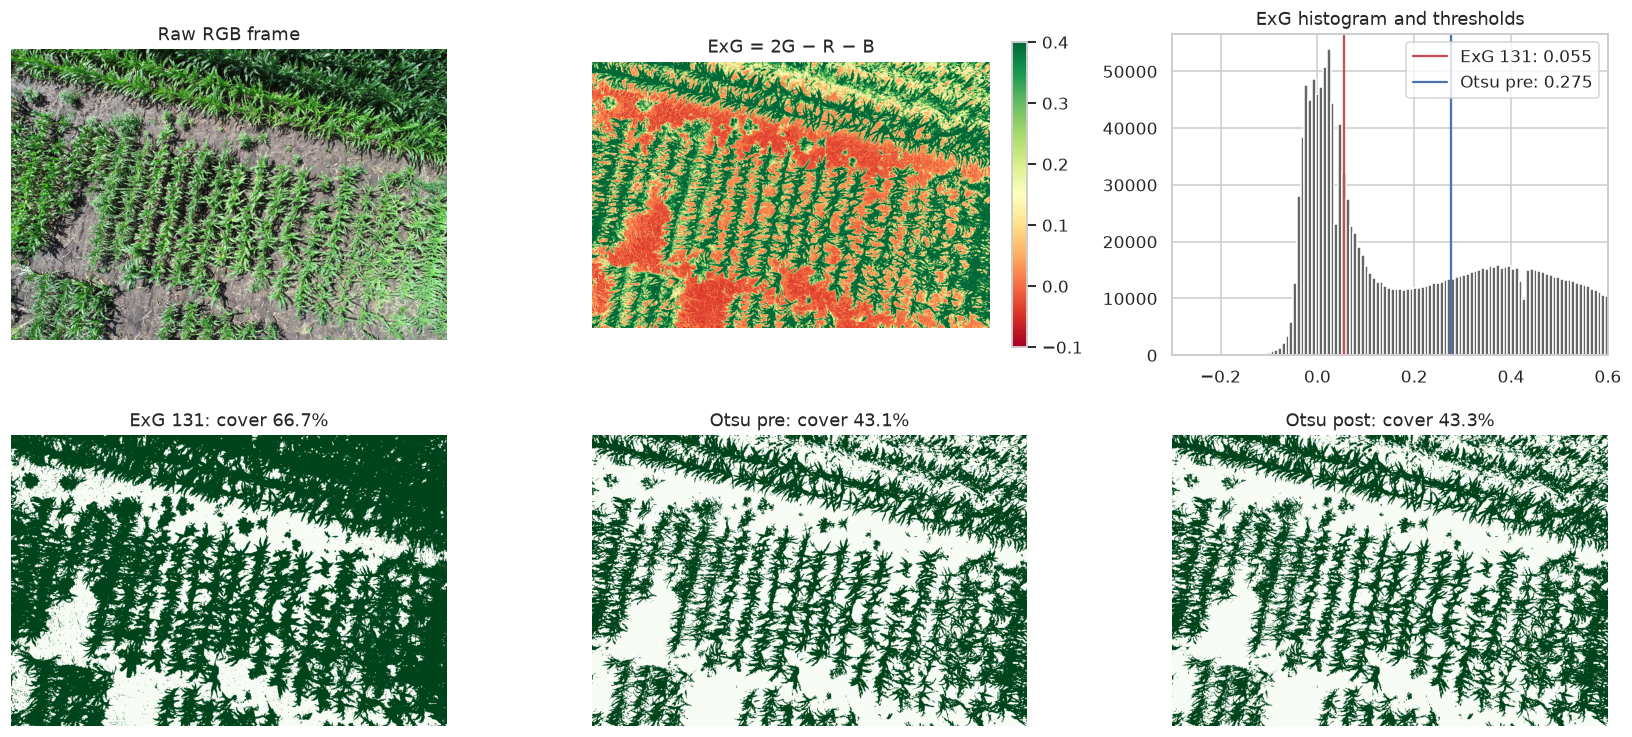

In [9]:
img = frames["frame_plots"]                                          # frame over two-row plots
R, G, B = (img.sel(band=c).values.astype("float64") * 255 for c in ("red", "green", "blue"))  # 8-bit channels
masks = foliage_masks(R, G, B)                                       # three foliage masks
exg = (2 * G - R - B) / 255                                          # ExG for display

fig, axes = plt.subplots(2, 3, figsize=(15, 7))                      # image, ExG and masks
axes[0, 0].imshow(rs.uav.to_rgb_array(img)); axes[0, 0].set_title("Raw RGB frame")       # true colour
im0 = axes[0, 1].imshow(exg, cmap="RdYlGn", vmin=-0.1, vmax=0.4); axes[0, 1].set_title("ExG = 2G − R − B")
plt.colorbar(im0, ax=axes[0, 1], fraction=0.035)                     # ExG scale
axes[0, 2].hist(exg.ravel(), bins=200, color="0.4")                  # bimodal soil/foliage histogram
for name, thr, c in [("ExG 131", 131 / 255 * 4 - 2, "C3"), ("Otsu pre", threshold_otsu(exg), "C0")]:
    axes[0, 2].axvline(thr, color=c, label=f"{name}: {thr:.3f}")     # mark each threshold
axes[0, 2].legend(); axes[0, 2].set_title("ExG histogram and thresholds"); axes[0, 2].set_xlim(-0.3, 0.6)
for ax, (name, m) in zip(axes[1], masks.items()):                    # one panel per mask
    ax.imshow(m, cmap="Greens"); ax.set_title(f"{name}: cover {100 * m.mean():.1f}%")
for ax in axes.ravel()[[0, 1, 3, 4, 5]]:                             # hide pixel axes
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures/pixel_masks.png"); plt.show()

The ExG histogram is bimodal: a soil peak near zero and a foliage shoulder above it. The fixed threshold 131
(ExG ≈ 0.055) sits low in the valley and keeps faint leaves; Otsu places the cut where between-class variance is
largest, which moves with the soil/foliage mix of each plot. A fixed threshold therefore gives comparable coverage
across plots and dates as long as exposure is stable, which is exactly why exposure needs to be controlled.

Next we compare our NumPy indices with GeoLattice and compute the plot traits on a window that mimics a clipped
two-row plot.

In [10]:
py = rs.uav.vegetation_indices(img, ["ExG", "VARI", "GLI", "NGRDI"])  # GeoLattice RGB indices on 0-1 data
mine = paper_indices(R, G, B)                                        # paper formulas on 8-bit data
for ours, theirs in [("ExG_raw", "ExG"), ("VARI", "VARI"), ("GLI", "GLI"), ("NGRDI", "NGRDI")]:
    a, b = mine[ours], py[theirs].values                             # same index from both routes
    ok = np.isfinite(a) & np.isfinite(b) & (np.abs(a) < 10)          # ignore division blow-ups
    print(f"{theirs:6s} max |difference| = {np.abs(a[ok] - b[ok]).max():.2e}")
py_mask = rs.uav.exg_plant_mask(img)                                 # GeoLattice Otsu-on-ExG mask with cleaning
print(f"GeoLattice exg_plant_mask cover: {100 * py_mask.mean():.1f}% "
      f"(Otsu pre without cleaning: {100 * masks['Otsu pre'].mean():.1f}%)")

ExG    max |difference| = 1.04e-07
VARI   max |difference| = 1.11e-06
GLI    max |difference| = 9.90e-08
NGRDI  max |difference| = 7.00e-08
GeoLattice exg_plant_mask cover: 47.7% (Otsu pre without cleaning: 43.1%)


In [11]:
h, w = img.sizes["y"], img.sizes["x"]                                # frame size
clip = img.isel(y=slice(int(0.25 * h), int(0.75 * h)), x=slice(int(0.35 * w), int(0.65 * w)))  # plot-like window
Rc, Gc, Bc = (clip.sel(band=c).values.astype("float64") * 255 for c in ("red", "green", "blue"))
rows = []                                                            # traits per filter
for name, m in foliage_masks(Rc, Gc, Bc).items():                    # same clip, three masks
    rows.append({"filter": name, **plot_traits(clip, m)})            # coverage, VIs, saturation
clip_traits = pd.DataFrame(rows).set_index("filter")                 # filter x trait table
clip_traits["light_value"] = light_value(FILES["frame_plots"])       # frame-level exposure
clip_traits.round(3)

,canopy_cover_pct,saturation,ExG_raw,ExG,RGBVI,NGRDI,GLI,MGRVI,VARI,VEG,Woebbecke,light_value
filter,,,,,,,,,,,,
ExG 131,59.815,91.420,0.390,0.330,0.412,0.186,0.223,0.344,0.273,1.619,1.946,12.966
Otsu pre,43.122,104.595,0.486,0.379,0.464,0.219,0.254,0.404,0.321,1.731,1.321,12.966
Otsu post,42.313,104.868,0.490,0.382,0.466,0.221,0.256,0.407,0.322,1.737,1.315,12.966


The VI averages change with the mask because each mask admits a different share of soil-contaminated edge pixels.
This is the same table the authors produced for every reference-replicate plot clip of every date, which is what we
load next.

## Choosing the foliage filter

The authors computed canopy coverage with all four filters and picked the one that best separated +N from −N on the
hybrid checks (`doc/fig2_cc_check.Rmd`). The checks are one genotype, so differences between quadrants are
treatment (plus quadrant) effects, not genetics. We repeat the test: Welch's t-test of check coverage (+N vs −N),
pooled over dates, for each filter, after dropping clips with less than 20% cover (failed clips).

In [12]:
cc_check = pd.read_csv(FILES["cc_check"])                            # check plots, 4 filters x 12 dates
cc_geno = pd.read_csv(FILES["cc_geno"])                              # genotype plots, 4 filters x 12 dates
print(cc_check.shape, cc_geno.shape)
cc_check.head(3)

(6240, 19) (42140, 19)


,Row,Filename,Plot,Row.Numbers,Filter.Type,Genotype.x,Image,Light.Value,Average.Saturation,Reference.Rep,Pixels.Remaining,Total,Percent.Cover,file,date,Pedigree,Genotype.y,Treatment,Rep
0,1017,190901_djifc6310s_Sept1_NE_row_34_range_6_rep_...,190901_djifc6310s_Sept1_NE_row_34_range_6,1017 and 1018,ExG 131,Check,DJI_0201.JPG,12.977566,22.014103,1,291016,385899,75.412478,data/CanopyCoverage/NE/Plot1_canopy_ref_sat_Se...,Sept1,Check,Check,Nitrogen,1
1,1017,190901_djifc6310s_Sept1_NE_row_34_range_6_rep_...,190901_djifc6310s_Sept1_NE_row_34_range_6,1017 and 1018,Custom,Check,DJI_0201.JPG,12.977566,21.971876,1,274174,385899,71.048124,data/CanopyCoverage/NE/Plot1_canopy_ref_sat_Se...,Sept1,Check,Check,Nitrogen,1
2,1017,190816_djifc6310s_Aug16_NE_row_34_range_6_rep_...,190816_djifc6310s_Aug16_NE_row_34_range_6,1017 and 1018,ExG 131,Check,DJI_0977.JPG,8.000000,23.263850,1,334227,449167,74.410409,data/CanopyCoverage/NE/Plot1_canopy_ref_sat_Au...,Aug16,Check,Check,Nitrogen,1


In [13]:
ck = cc_check[cc_check["Percent.Cover"] > 20]                        # drop failed clips, as in the paper
filt = []                                                            # one row per filter
for f, sub in ck.groupby("Filter.Type"):                             # each pixel filter
    pn = sub.loc[sub.Treatment == "Nitrogen", "Percent.Cover"]       # +N coverage
    mn = sub.loc[sub.Treatment == "No Nitrogen", "Percent.Cover"]    # -N coverage
    t = stats.ttest_ind(pn, mn, equal_var=False)                     # Welch t-test
    filt.append({"filter": f, "+N mean": pn.mean(), "-N mean": mn.mean(),
                 "difference": pn.mean() - mn.mean(), "t": t.statistic, "p": t.pvalue})
filt = pd.DataFrame(filt).sort_values("t", ascending=False)          # strongest separation first
filt.round(4)

,filter,+N mean,-N mean,difference,t,p
1,ExG 131,83.3229,74.2828,9.0401,23.6186,0.0
0,Custom,77.9324,70.3203,7.6120,18.5718,0.0
3,Otsu pre,61.3526,54.3436,7.0089,13.8508,0.0
2,Otsu post,59.9562,54.0014,5.9548,11.9496,0.0


The fixed **ExG 131** filter gives the largest t statistic, so, like the authors, we use ExG 131 for everything
that follows. Otsu thresholds adapt to each clip, which partly normalises away the very canopy difference we want
to detect.

## Light, saturation and VI normalisation

The camera set exposure automatically, and some flights were late in the evening (Aug 16, Aug 26, Sept 3), while
July 6 used different camera settings. RGB VIs respond to both brightness and colour saturation (Supplementary
Figure S3 of the paper), so the authors divided every VI by the frame's light value and the clip's mean saturation:

VI_norm = VI / (LV × S̄)

We load the reference-replicate VI table, keep the ExG 131 filter, inspect exposure per date and apply the
normalisation.

In [14]:
vi_raw = pd.read_csv(FILES["vi_plots"])                              # plot VIs, all filters, 12 dates
vi = vi_raw[vi_raw["Filter.Type"] == "ExG 131"].copy()               # chosen filter
vi["quadrant"] = vi.Plot.str.extract(r"_(NE|NW|SE|SW)_")[0]          # quadrant from the clip name
vi[["fcol", "frange"]] = vi.Plot.str.extract(r"_row_(\d+)_range_(\d+)").astype(int)  # field coordinates
vi["is_check"] = vi["Genotype.x"].eq("Check")                        # hybrid check flag
print(f"{len(vi):,} plot-date records, {vi.Row.nunique()} plots, {vi.date.nunique()} dates")
expo = (vi.groupby("date")[["Light.Value", "Average.Saturation"]]    # exposure summary per flight
          .agg(["min", "median", "max"]).round(2).reindex(DATES))
expo

11,591 plot-date records, 1008 plots, 12 dates


Light.Value               Average.Saturation              
              min median    max                min median    max
date                                                            
July6       12.55  12.55  12.55              47.60  65.97  86.94
Aug12       10.23  10.64  10.64              14.81  26.08  41.24
Aug14       12.31  12.63  13.30              15.95  28.38  47.06
Aug16        6.94   7.61   8.32              11.05  20.51  40.60
Aug20       10.64  11.95  12.63              14.84  27.97  45.80
Aug22       10.64  11.29  11.95              15.36  24.95  40.24
Aug23       10.97  11.29  12.98              17.37  30.58  50.58
Aug26        7.20   8.00   8.32              19.28  35.89  68.97
Aug30       11.29  11.61  11.95              14.60  25.23  41.48
Sept1       10.97  12.63  12.98              13.47  24.56  43.69
Sept3        8.32   8.59   8.92              13.90  26.43  50.52
Sept5       12.31  12.63  12.98              16.92  27.65  49.97

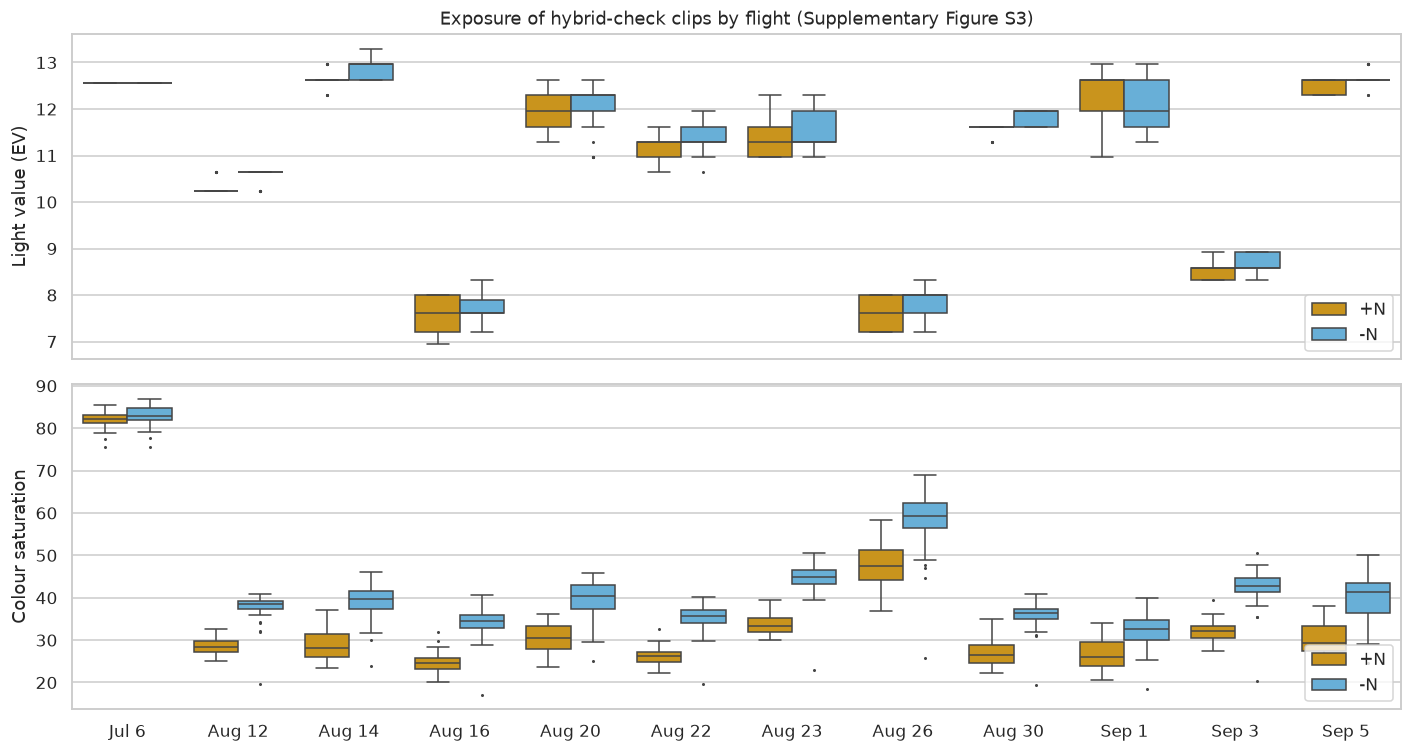

In [15]:
chk = vi[vi.is_check].copy()                                         # checks only for exposure plots
chk["date_lab"] = pd.Categorical(chk.date.map(LABEL), [LABEL[d] for d in DATES], ordered=True)  # ordered dates
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)         # LV and saturation by date
for ax, col, lab in zip(axes, ["Light.Value", "Average.Saturation"], ["Light value (EV)", "Colour saturation"]):
    sns.boxplot(data=chk, x="date_lab", y=col, hue="Treatment", palette=TRT_COL, ax=ax, fliersize=1)  # per trt
    ax.set_ylabel(lab); ax.set_xlabel("")                            # axis labels
    ax.legend(handles=ax.get_legend_handles_labels()[0], labels=["+N", "-N"], loc="lower right")
axes[0].set_title("Exposure of hybrid-check clips by flight (Supplementary Figure S3)")
plt.tight_layout(); plt.savefig(OUT / "figures/light_saturation.png"); plt.show()

In [16]:
VI_COLS = ["ExG", "ExG2", "RGB", "NGR", "GLI", "MGR", "VARI", "VEG", "Woebbecke..no.abs.", "Woebbecke..abs."]
vin = vi.copy()                                                      # normalised copy
vin[VI_COLS] = vin[VI_COLS].div(vin["Light.Value"], axis=0).div(vin["Average.Saturation"], axis=0)  # VI/(LV*S)
vin[VI_COLS] *= 1000                                                 # x1000, as in the paper's tables
vin = vin.drop(columns=["ExG", "Woebbecke..no.abs."]).rename(columns=VI8)  # keep the 8 paper VIs, paper names

cmp = pd.DataFrame({"VEG raw": vi[vi.is_check].groupby("date").VEG.median(),          # check medians per flight
                    "VEG normalised": vin[vin.is_check].groupby("date").VEG.median()}).reindex(DATES)
cmp.round(3)

,VEG raw,VEG normalised
date,,
July6,1.730,1.678
Aug12,1.186,3.526
Aug14,1.181,2.719
Aug16,1.173,5.231
Aug20,1.186,2.877
Aug22,1.162,3.319
Aug23,1.235,2.665
Aug26,1.222,2.976
Aug30,1.164,3.101


Read the table carefully. Raw check VEG is nearly flat across August and September, but normalised VEG jumps on
the dark Aug 16 and Sept 3 flights, because dividing by a low light value inflates the index. The normalisation is
therefore mainly a *within-flight* correction: the light value is almost constant within a flight, while saturation
varies from clip to clip and removes plot-to-plot colour differences caused by the camera. Normalised VIs should be
compared between plots of the same date (as the paper does for every correlation and GWAS), not between dates. Note
also that July 6 has by far the highest saturation: a different camera setting, which the authors flag as a
limitation.

**[CHECK]** 11,591 ExG 131 records (1,008 plots × 12 dates, minus missing clips) and no infinite normalised values.

In [17]:
assert len(vin) == 11591 and np.isfinite(vin[list(VI8.values())].to_numpy(dtype=float)).all()  # [CHECK]

## Canopy coverage response to nitrogen

Two questions, as in Figure 2 of the paper:

* **Hybrid checks (Figure 2A).** Is check canopy coverage higher under +N on each date? Welch's t-test with
  Benjamini-Hochberg FDR across the 12 dates.
* **Inbred lines (Figure 2B).** For each genotype and date, average the replicates within each treatment and form
  the ratio +N/−N. A paired t-test (each genotype is its own control) asks whether +N coverage is higher on average.

In [18]:
cg = cc_geno[cc_geno["Filter.Type"] == "ExG 131"]                    # ExG 131 genotype coverage
gm = (cg.groupby(["date", "Treatment", "Pedigree"])["Percent.Cover"].mean()  # rep means per treatment
        .unstack("Treatment").dropna())                              # genotypes present in both treatments
gm["ratio"] = gm["Nitrogen"] / gm["No Nitrogen"]                     # +N / -N ratio

geno_test = []                                                       # paired tests per date
for d in DATES:                                                      # in flight order
    x = gm.loc[d]                                                    # one date
    t = stats.ttest_rel(x["Nitrogen"], x["No Nitrogen"])             # paired t-test across genotypes
    geno_test.append({"date": LABEL[d], "n_geno": len(x), "diff": (x["Nitrogen"] - x["No Nitrogen"]).mean(),
                      "mean_ratio": x.ratio.mean(), "p": t.pvalue})
geno_test = pd.DataFrame(geno_test)                                  # table of results
geno_test["fdr"] = multipletests(geno_test.p, method="fdr_bh")[1]    # FDR across dates

pub = pd.read_csv(FILES["pub_cc_geno"])                              # published values (Figure 2B)
assert np.allclose(geno_test.p, pub.pval) and np.allclose(geno_test.mean_ratio, pub.ratio)  # [CHECK] exact
geno_test.round(4)

,date,n_geno,diff,mean_ratio,p,fdr
0,Jul 6,225,6.1832,1.2436,0.0000,0.0000
1,Aug 12,225,2.7568,1.0908,0.0000,0.0001
2,Aug 14,225,-0.0312,1.0380,0.9674,0.9674
3,Aug 16,225,1.9914,1.0656,0.0073,0.0087
4,Aug 20,225,2.4133,1.1024,0.0016,0.0027
5,Aug 22,225,3.5368,1.1262,0.0000,0.0000
6,Aug 23,225,3.8339,1.1126,0.0000,0.0000
7,Aug 26,225,4.3106,1.1081,0.0000,0.0000
8,Aug 30,225,2.2082,1.1184,0.0072,0.0087
9,Sep 1,225,3.8599,1.1712,0.0000,0.0000


In [19]:
ck131 = ck[ck["Filter.Type"] == "ExG 131"]                           # checks with >20% cover
check_test = []                                                      # Welch tests per date
for d in DATES:                                                      # in flight order
    s = ck131[ck131.date == d]                                       # one date
    pn, mn = s.loc[s.Treatment == "Nitrogen", "Percent.Cover"], s.loc[s.Treatment == "No Nitrogen", "Percent.Cover"]
    check_test.append({"date": LABEL[d], "n_+N": len(pn), "n_-N": len(mn), "+N": pn.mean(), "-N": mn.mean(),
                       "diff": pn.mean() - mn.mean(), "p": stats.ttest_ind(pn, mn, equal_var=False).pvalue})
check_test = pd.DataFrame(check_test)                                # results table
check_test["fdr"] = multipletests(check_test.p, method="fdr_bh")[1]  # FDR
pub_ck = pd.read_csv(FILES["pub_cc_check"])                          # published Figure 2A statistics
check_test["published_diff"] = pub_ck["diff"].values                 # for comparison
check_test["published_p"] = pub_ck["pval"].values
check_test.round(4)

,date,n_+N,n_-N,+N,-N,diff,p,fdr,published_diff,published_p
0,Jul 6,64,65,69.5355,59.4230,10.1125,0.0,0.0,7.9728,0.0000
1,Aug 12,64,65,87.5300,79.2846,8.2455,0.0,0.0,10.4700,0.0000
2,Aug 14,64,65,84.3368,77.4236,6.9132,0.0,0.0,3.3249,0.0004
3,Aug 16,64,65,84.0276,74.0084,10.0192,0.0,0.0,5.3029,0.0000
4,Aug 20,64,65,84.9665,74.9520,10.0145,0.0,0.0,4.5488,0.0000
5,Aug 22,64,65,84.3275,75.7314,8.5961,0.0,0.0,10.9609,0.0000
6,Aug 23,64,65,87.9744,79.2465,8.7279,0.0,0.0,10.5296,0.0000
7,Aug 26,64,65,89.2822,80.4796,8.8026,0.0,0.0,6.2984,0.0001
8,Aug 30,64,65,85.2740,76.5148,8.7592,0.0,0.0,10.4140,0.0000
9,Sep 1,64,65,86.4154,76.3394,10.0760,0.0,0.0,9.0035,0.0000


The genotype-level results reproduce the published statistics exactly (the assertion above passes). For the
checks, the direction agrees on every date but our differences are larger and the p-values smaller than the
published ones. The published check statistics were computed from all replicate images of every check plot (a
larger table that is not in the repository), whereas we only have the single most nadir reference replicate per
plot. Off-nadir replicates see the canopy at an angle, mix in neighbouring rows and add noise, which dilutes the
difference: one concrete reason the paper insists on reference replicates.

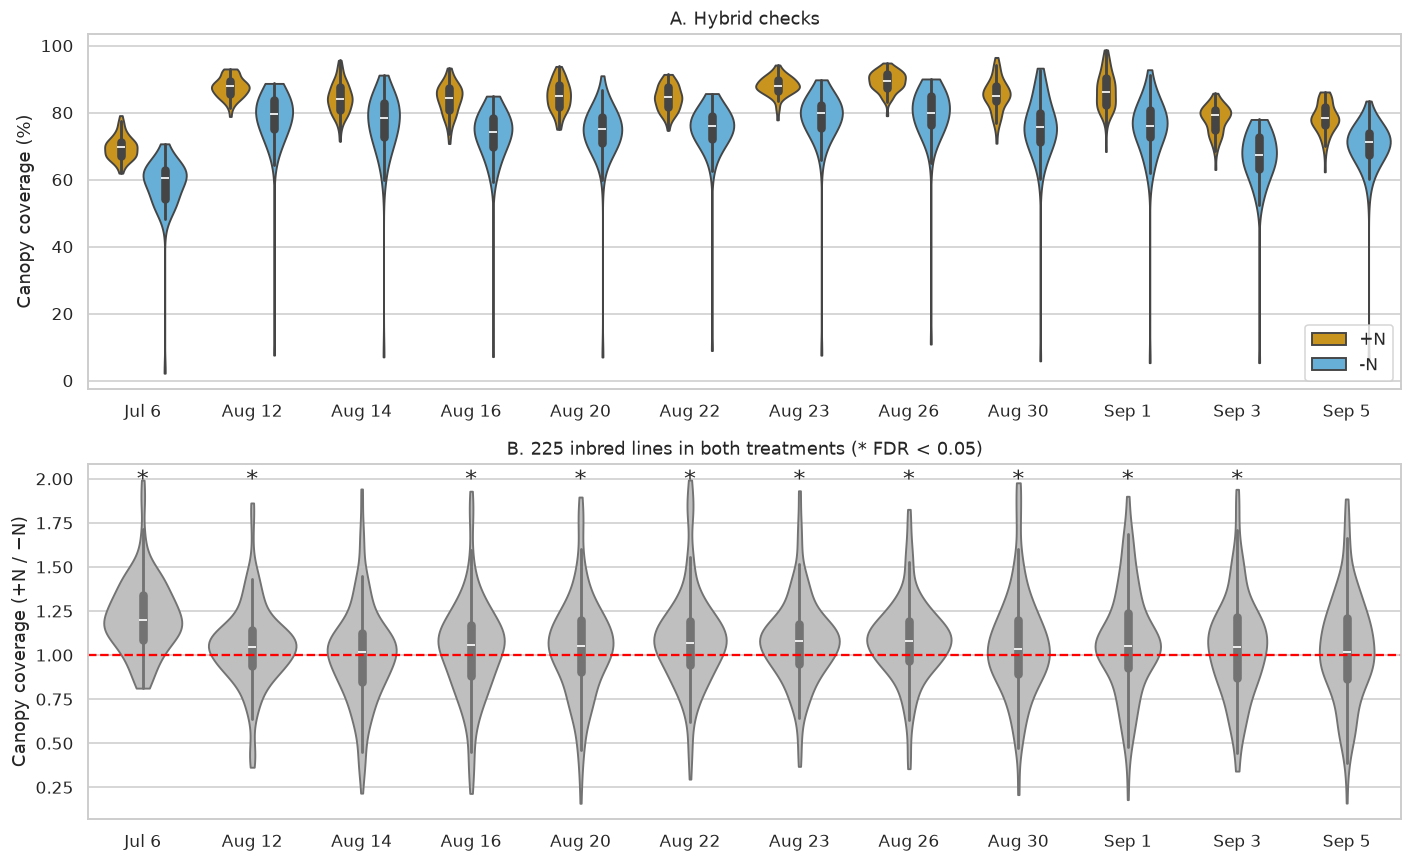

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))                      # Figure 2A and 2B
c131 = cc_check[cc_check["Filter.Type"] == "ExG 131"].copy()         # all check clips
c131["date_lab"] = pd.Categorical(c131.date.map(LABEL), [LABEL[d] for d in DATES], ordered=True)
sns.violinplot(data=c131, x="date_lab", y="Percent.Cover", hue="Treatment", palette=TRT_COL,
               cut=0, inner="box", ax=axes[0])                       # check coverage by treatment
axes[0].legend(handles=axes[0].get_legend_handles_labels()[0], labels=["+N", "-N"], loc="lower right")
axes[0].set(xlabel="", ylabel="Canopy coverage (%)", title="A. Hybrid checks")
gr = gm.reset_index()                                                # genotype ratios, long form
gr = gr[gr.ratio < 2]                                                # trim extreme ratios for display, as the paper
gr["date_lab"] = pd.Categorical(gr.date.map(LABEL), [LABEL[d] for d in DATES], ordered=True)
sns.violinplot(data=gr, x="date_lab", y="ratio", color="0.75", cut=0, inner="box", ax=axes[1])  # ratio violins
axes[1].axhline(1, color="red", ls="--")                             # no N response
for i, (p, r) in enumerate(zip(geno_test.fdr, geno_test.mean_ratio)):  # mark significant dates
    if p < 0.05:
        axes[1].text(i, 1.95, "*", ha="center", fontsize=16)
axes[1].set(xlabel="", ylabel="Canopy coverage (+N / −N)", title=f"B. {len(gm.loc[DATES[0]])} inbred lines in both treatments (* FDR < 0.05)")
plt.tight_layout(); plt.savefig(OUT / "figures/fig2_canopy_coverage.png"); plt.show()

In [21]:
gen_ratio = gm.ratio.groupby("Pedigree").mean()                      # season-mean ratio per genotype
print(f"Genotypes with season-mean ratio > 1.5: {(gen_ratio > 1.5).sum()}; "
      f"< 0.8: {(gen_ratio < 0.8).sum()} of {len(gen_ratio)}")
print(f"Genotypes with ratio < 0.8 on at least one date: {(gm.ratio < 0.8).groupby('Pedigree').any().sum()}")
consist = gm.ratio.unstack("date")[DATES].corr(method="spearman")    # rank stability of ratios across dates
off = consist.where(~np.eye(12, dtype=bool)).stack()                 # off-diagonal correlations
print(f"Spearman correlation of genotype ratios between dates: median {off.median():.2f}")

Genotypes with season-mean ratio > 1.5: 17; < 0.8: 25 of 225
Genotypes with ratio < 0.8 on at least one date: 72
Spearman correlation of genotype ratios between dates: median 0.74


Most lines respond positively to N early in the season (mean ratio 1.24 on July 6), and the response shrinks as
plants mature, since the N was applied before planting. The paper reports 17 genotypes with a ratio above 1.5,
which matches our season-mean ratio. Its count of 76 genotypes with ratio below 0.8 is not reproduced by the
season mean (25) and is close to the 72 genotypes that fall below 0.8 on at least one date, so the exact definition
used is unclear; such ambiguities are common in supplementary analyses and worth noting when replicating. Genotype
ratios are fairly consistent between dates (median Spearman correlation 0.74), as the paper notes.

## Vegetation index response to nitrogen

Do the *normalised* greenness indices also separate +N from −N? For the hybrid checks we fit, for each VI,

VI_norm ~ Treatment + date

so the treatment effect is tested after removing date-to-date shifts (the paper's `pval_check_VIs.csv`). Most indices
should be higher under +N (greener leaves), while Woebbecke behaves in the opposite direction.

In [22]:
chk_n = vin[vin.is_check]                                            # normalised check VIs
vi_trt = []                                                          # one model per VI
for v in VI8.values():                                               # eight indices
    fit = smf.ols(f"Q('{v}') ~ C(Treatment, levels=['No Nitrogen', 'Nitrogen']) + C(date)", data=chk_n).fit()  # -N baseline
    term = [k for k in fit.params.index if k.startswith("C(Treatment")][0]  # the +N effect term
    vi_trt.append({"VI": v, "+N effect": fit.params[term], "t": fit.tvalues[term], "p": fit.pvalues[term]})
vi_trt = pd.DataFrame(vi_trt)                                        # results table
vi_trt

,VI,+N effect,t,p
0,ExG,0.052442,41.364540,6.930301e-249
1,RGBVI,0.071302,42.222887,5.088189e-256
2,NGRDI,0.074810,47.878858,1.417023e-302
3,GLI,0.039141,42.964638,3.569110e-262
4,MGRVI,0.147612,47.756137,1.414996e-301
5,VARI,0.144709,47.921727,6.344562e-303
6,VEG,0.907197,44.119667,9.867538e-272
7,Woebbecke,-2.021734,-21.527676,1.326129e-89


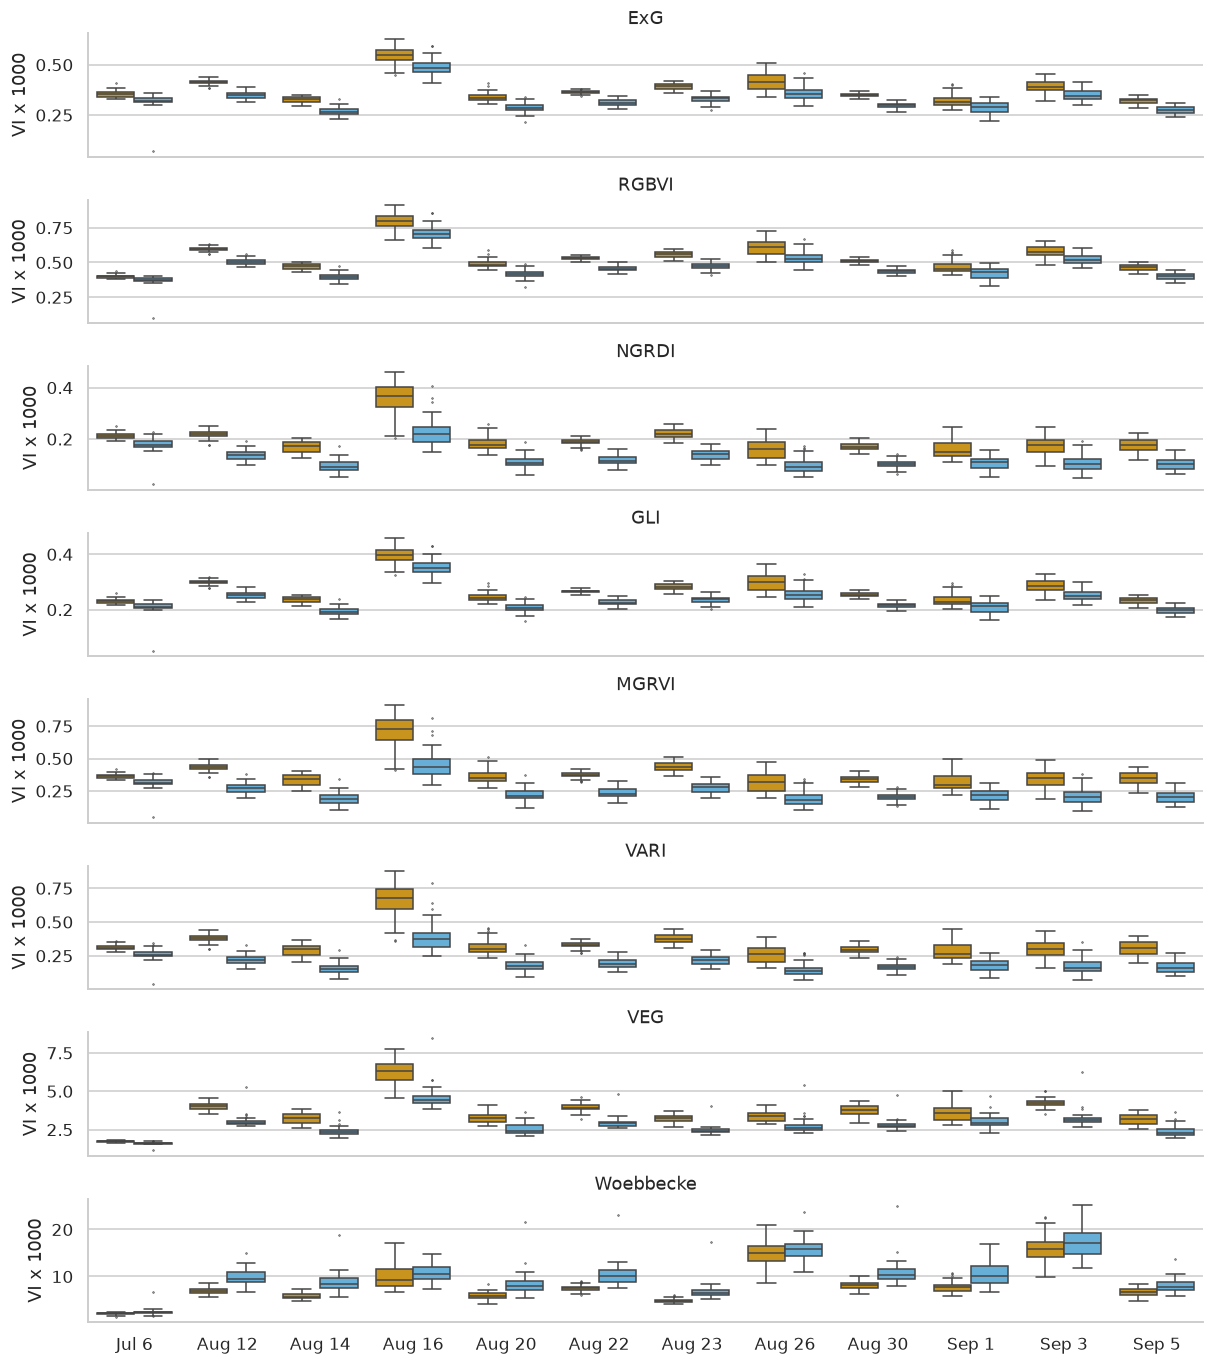

In [23]:
long = vin[vin.is_check].melt(id_vars=["date", "Treatment"], value_vars=list(VI8.values()),  # long format
                              var_name="VI", value_name="value")
long["date_lab"] = pd.Categorical(long.date.map(LABEL), [LABEL[d] for d in DATES], ordered=True)
g = sns.catplot(data=long, x="date_lab", y="value", hue="Treatment", row="VI", kind="box", palette=TRT_COL,
                height=1.6, aspect=7, sharey=False, fliersize=0.5, legend=False)  # Supplementary Figure S4
g.set_axis_labels("", "VI x 1000"); g.set_titles("{row_name}")       # labels
plt.savefig(OUT / "figures/vi_checks_by_date.png"); plt.show()

In [24]:
gv = (vin[~vin.is_check].groupby(["date", "Treatment", "Pedigree"])[list(VI8.values())].mean()  # rep means
        .unstack("Treatment"))
ratio_vi = pd.DataFrame({v: (gv[(v, "Nitrogen")] / gv[(v, "No Nitrogen")]) for v in VI8.values()})  # +N/-N
print("Median genotype VI ratio (+N/-N) over all dates:")
print(ratio_vi.median().round(3).to_string())

Median genotype VI ratio (+N/-N) over all dates:
ExG          1.080
RGBVI        1.074
NGRDI        1.316
GLI          1.082
MGRVI        1.313
VARI         1.360
VEG          1.167
Woebbecke    0.922


All indices except Woebbecke are higher under +N on the checks, and the genotype ratios deviate from 1 in the same
directions (Supplementary Figures S4 and S5): after normalisation, the RGB indices carry an N signal.

## VIs as predictors of leaf and yield traits

Ground truth was measured on the same plots: **leaf nitrogen** (%), **leaf area** (cm², three sampled leaves) and
leaf nutrients from leaf samples, and **20-kernel weight** (g) from hand-harvested ears. For each date and VI we
compute the Pearson correlation with each trait (Figure 3A), then look at the best pairs on August 22 (Figure 3B to
3D). Plot ids join the tables: `Row` in the image table equals `Plant id` in the leaf table and `row` in the yield
table.

In [25]:
leaf = pd.read_csv(FILES["leaf"], usecols=range(17), low_memory=False)  # leaf traits (spectra columns skipped)
leaf["Chl"] = pd.to_numeric(leaf["Chl"], errors="coerce")            # chlorophyll has text entries
yld = pd.read_csv(FILES["yield"])                                    # kernel and cob traits
print(f"Leaf samples: {len(leaf)} plots; yield samples: {yld['Weight.of.20.seeds'].notna().sum()} plots")
truth = (leaf.rename(columns={"Plant id": "Row", "LA": "Leaf area", "Nitrogen": "Leaf N"})  # unify keys
             [["Row", "Leaf N", "Leaf area", "Chl"]]
         .merge(yld.rename(columns={"row": "Row", "Weight.of.20.seeds": "20 kernel weight"})
                [["Row", "20 kernel weight"]], on="Row", how="outer"))
TRAITS = ["Leaf N", "Leaf area", "20 kernel weight"]                 # the three traits of Figure 3
vt = vin.merge(truth, on="Row", how="inner")                         # image traits joined to ground truth
truth[TRAITS].describe().round(2)

Leaf samples: 499 plots; yield samples: 519 plots


,Leaf N,Leaf area,20 kernel weight
count,498.00,499.00,519.00
mean,2.66,1084.69,4.92
std,0.55,311.84,1.09
min,1.23,355.08,1.70
25%,2.22,863.05,4.20
50%,2.76,1069.00,5.00
75%,3.08,1287.35,5.70
max,4.11,2333.91,7.90


In [26]:
cor_rows = []                                                        # trait x VI x date correlations
for (d, trait, v) in [(d, t, v) for d in DATES for t in TRAITS for v in VI8.values()]:
    s = vt.loc[vt.date == d, [v, trait]].dropna()                    # complete pairs only
    r, p = stats.pearsonr(s[v], s[trait])                            # Pearson correlation
    cor_rows.append({"date": d, "trait": trait, "VI": v, "r": r, "p": p, "n": len(s)})
cors = pd.DataFrame(cor_rows)                                        # long table of correlations
cors.to_csv(OUT / "tables/vi_trait_correlations.csv", index=False)   # export
summary = cors.assign(abs_r=cors.r.abs()).groupby("trait").abs_r.agg(["mean", "std", "max"]).round(2)
summary                                                              # paper: 0.27, 0.24, 0.16 mean |r|

,mean,std,max
trait,,,
20 kernel weight,0.25,0.14,0.41
Leaf N,0.27,0.18,0.73
Leaf area,0.33,0.14,0.54


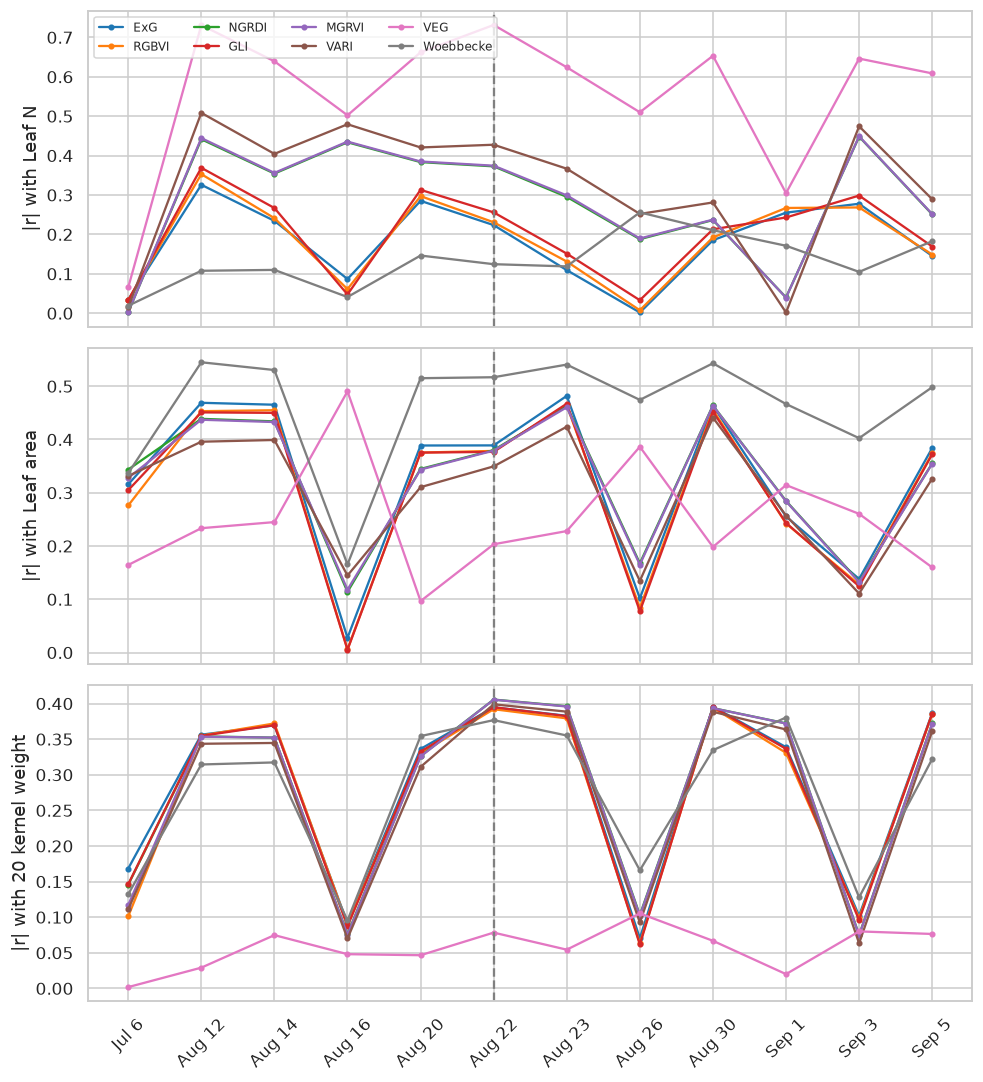

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)         # Figure 3A
pal = dict(zip(VI8.values(), sns.color_palette("tab10", 8)))         # one colour per VI
for ax, trait in zip(axes, TRAITS):                                  # one panel per trait
    for v in VI8.values():                                           # one line per VI
        s = cors[(cors.trait == trait) & (cors.VI == v)].set_index("date").loc[DATES]
        ax.plot([LABEL[d] for d in DATES], s.r.abs(), marker="o", ms=3, color=pal[v], label=v)
    ax.axvline(LABEL["Aug22"], color="0.5", ls="--")                 # selected date
    ax.set_ylabel(f"|r| with {trait}")                               # panel label
axes[0].legend(ncol=4, fontsize=8, loc="upper left")
plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(OUT / "figures/fig3a_correlations.png"); plt.show()

In [28]:
best = cors.loc[cors.groupby("trait").r.apply(lambda s: s.abs().idxmax())]  # strongest |r| per trait
print(best[["trait", "date", "VI", "r", "p", "n"]].round(4).to_string(index=False))

           trait  date        VI       r   p   n
20 kernel weight Aug22     NGRDI  0.4055 0.0 519
          Leaf N Aug22       VEG  0.7313 0.0 498
       Leaf area Aug12 Woebbecke -0.5449 0.0 499


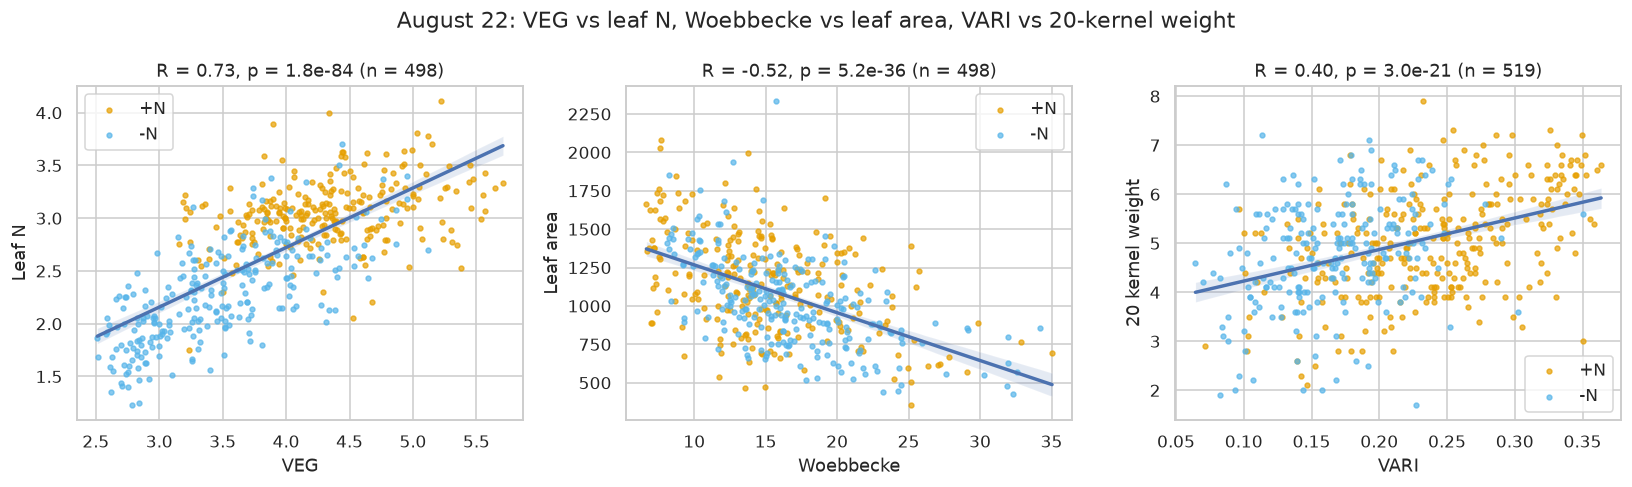

In [29]:
pairs = [("VEG", "Leaf N"), ("Woebbecke", "Leaf area"), ("VARI", "20 kernel weight")]  # Figure 3B to 3D
a22 = vt[vt.date == "Aug22"]                                         # selected flight
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))                    # three scatter plots
for ax, (v, trait) in zip(axes, pairs):                              # each VI-trait pair
    s = a22[[v, trait, "Treatment"]].dropna()                        # complete cases
    if v == "Woebbecke":                                             # the paper drops a few extreme values
        s = s[s[v] < 40]
    r, p = stats.pearsonr(s[v], s[trait])                            # correlation
    sns.regplot(data=s, x=v, y=trait, ax=ax, scatter=False, color="C0")  # fit with 95% CI
    for trt, c in TRT_COL.items():                                   # points by treatment
        q = s[s.Treatment == trt]
        ax.scatter(q[v], q[trait], s=10, color=c, label=TRT_LAB[trt], alpha=0.7)
    ax.set_title(f"R = {r:.2f}, p = {p:.1e} (n = {len(s)})"); ax.legend()
plt.suptitle("August 22: VEG vs leaf N, Woebbecke vs leaf area, VARI vs 20-kernel weight")
plt.tight_layout(); plt.savefig(OUT / "figures/fig3bcd_scatter.png"); plt.show()

These reproduce the paper's headline values: VEG vs leaf N R = 0.73, Woebbecke vs leaf area R = −0.52 and VARI
vs 20-kernel weight R = 0.40 on August 22. Correlations dip on the low-light flights (Aug 16, Aug 26) even after
normalisation, so flight time of day remains a design variable you cannot fully correct afterwards. Part of the
strong VEG and leaf-N relation is the treatment itself (+N plots are greener and richer in N); within one treatment
the correlation is weaker, which you can check in the exercises.

## Season traits from the time series

Twelve flights let us summarise each genotype's season with a few robust traits instead of 12 correlated numbers:

* **max**: the highest canopy coverage, a proxy for maximum canopy size;
* **doy_max**: the day of year it was reached;
* **auc**: the area under the coverage curve (trapezoid rule, % × days), integrating size over time;
* **senescence rate**: the slope of coverage from Aug 23 to Sept 5 (% per day; negative = canopy loss);
* **N response**: the season-mean +N/−N ratio computed above.

There is a 37-day gap between July 6 and August 12, so "green-up" rates cannot be estimated reliably and are left
out. A 4-parameter logistic (`rs.uav.fit_logistic`) is fitted to the check means to illustrate curve fitting on the
senescing part of the season.

In [30]:
cc_long = cg.assign(doy=cg.date.map(DOY))                            # coverage with day of year
cc_gt = (cc_long.groupby(["Pedigree", "Treatment", "doy"])["Percent.Cover"].mean()  # rep mean per day
           .reset_index().sort_values("doy"))
LATE = [DOY[d] for d in ["Aug23", "Aug26", "Aug30", "Sept1", "Sept3", "Sept5"]]  # senescence window

def season_traits(df):
    """Max, timing, AUC and late-season slope of one genotype x treatment coverage curve."""
    t, y = df.doy.to_numpy(float), df["Percent.Cover"].to_numpy(float)  # time and coverage
    late = df.doy.isin(LATE)                                         # senescence flights
    slope = np.polyfit(t[late], y[late], 1)[0] if late.sum() >= 3 else np.nan  # linear decline rate
    return pd.Series({"max": y.max(), "doy_max": t[np.argmax(y)], "auc": np.trapezoid(y, t),
                      "senescence_rate": slope, "n_dates": len(t)})

season = cc_gt.groupby(["Pedigree", "Treatment"]).apply(season_traits).reset_index()  # one row per geno x trt
season = season[season.n_dates == 12]                                # complete curves only
season.groupby("Treatment")[["max", "doy_max", "auc", "senescence_rate"]].mean().round(2)

,max,doy_max,auc,senescence_rate
Treatment,,,,
Nitrogen,61.31,231.55,2917.34,-1.51
No Nitrogen,57.97,232.29,2701.28,-1.31


+N checks: logistic midpoint Sep 02, R2 = 0.72
-N checks: logistic midpoint Sep 01, R2 = 0.66


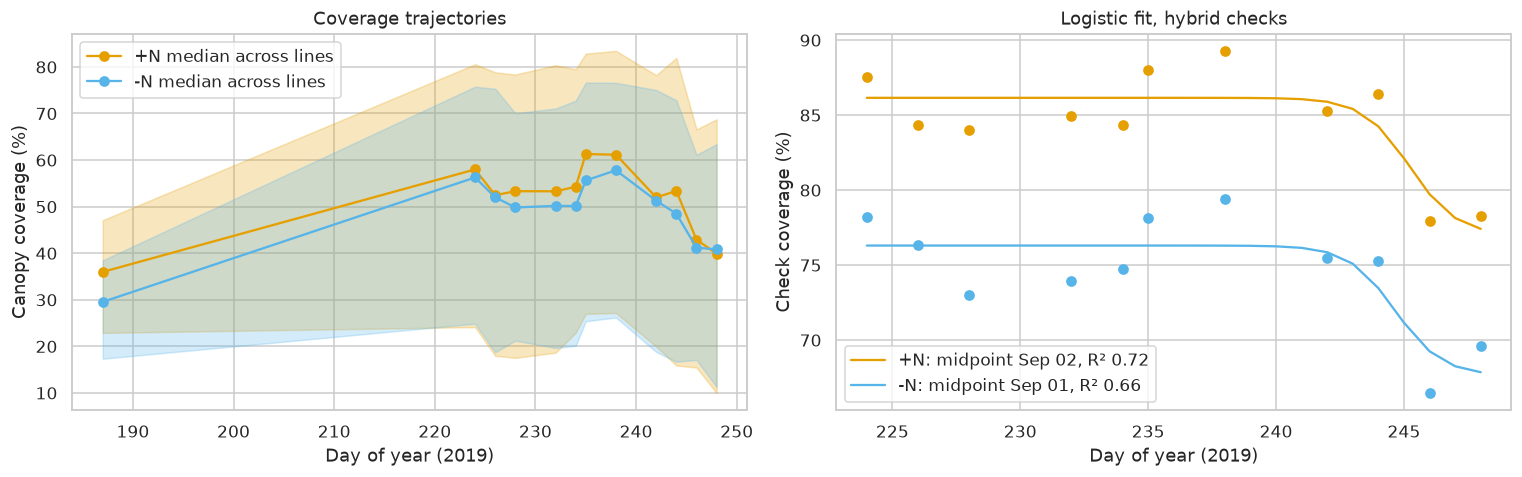

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))                    # curves and logistic fit
for trt, c in TRT_COL.items():                                       # per treatment
    sub = cc_gt[cc_gt.Treatment == trt]                              # genotype curves
    q = sub.groupby("doy")["Percent.Cover"].quantile([0.1, 0.5, 0.9]).unstack()  # spread across genotypes
    axes[0].fill_between(q.index, q[0.1], q[0.9], color=c, alpha=0.25)  # 10-90% band
    axes[0].plot(q.index, q[0.5], "o-", color=c, label=f"{TRT_LAB[trt]} median across lines")
axes[0].set(xlabel="Day of year (2019)", ylabel="Canopy coverage (%)", title="Coverage trajectories")
axes[0].legend()

for trt, c in TRT_COL.items():                                       # logistic fit to check senescence
    s = (c131[c131.Treatment == trt].assign(doy=lambda d: d.date.map(DOY))  # check clips by day
           .groupby("doy")["Percent.Cover"].mean())
    s = s[s.index >= DOY["Aug12"]]                                   # plateau and senescence phase
    dates = pd.to_datetime("2019-01-01") + pd.to_timedelta(s.index - 1, unit="D")  # back to calendar dates
    fit = rs.uav.fit_logistic(dates, s.values, decreasing=True)      # 4-parameter logistic
    grid = pd.date_range(dates.min(), dates.max(), freq="D")         # daily prediction grid
    axes[1].plot(s.index, s.values, "o", color=c)                    # observed check means
    print(f"{TRT_LAB[trt]} checks: logistic midpoint {fit['mid_date']:%b %d}, R2 = {fit['r2']:.2f}")  # fit quality
    axes[1].plot(grid.dayofyear, fit["predict"](grid), "-", color=c,
                 label=f"{TRT_LAB[trt]}: midpoint {fit['mid_date']:%b %d}, R² {fit['r2']:.2f}")
axes[1].set(xlabel="Day of year (2019)", ylabel="Check coverage (%)", title="Logistic fit, hybrid checks")
axes[1].legend(); plt.tight_layout(); plt.savefig(OUT / "figures/season_curves.png"); plt.show()

The flights capture the plateau and the start of senescence; the logistic fit is loose (the late-season decline is
noisy and partly driven by exposure), which is a reminder that more frequent and earlier flights are needed before
curve parameters can be treated as traits. The simple summaries (max, AUC, late slope) are more robust with this
sampling.

**[CHECK]** Season traits exist for over 200 genotypes per treatment, and every `doy_max` lies within the
flight window.

In [32]:
assert season.groupby("Treatment").size().min() > 200                # [CHECK] enough complete curves
assert season.doy_max.between(DOY["July6"], DOY["Sept5"]).all()      # [CHECK] timing inside the window

## Field trends and heritability

Before mapping genes we should know how much of a trait's variation is genetic. With two replicates (quadrants) per
treatment, a genotype model per date and treatment gives the variance components:

y = μ + rep + genotype + ε,  σ²_g = (MS_g − MS_e)/r,  H² = σ²_g / (σ²_g + σ²_e / r)

with r = 2 replicates. Field gradients (soil, drainage, edge effects) inflate σ²_e. Each quadrant has six ranges, and
plants were blocked by height and maturity, so we also fit range-within-quadrant as a fixed effect and see whether
H² improves. A field map of residual coverage shows whether such trends exist.

In [33]:
def heritability(df, trait, spatial=False):
    """Entry-mean broad-sense heritability from a two-rep genotype ANOVA (optionally range-adjusted)."""
    d = df.dropna(subset=[trait])                                    # complete records
    d = d[d.groupby("Pedigree")[trait].transform("size") == 2]       # genotypes with both reps
    if d.Pedigree.nunique() < 20:                                    # one replicate only (July 6 flight)
        return np.nan                                                # not estimable
    form = f"Q('{trait}') ~ C(quadrant) + C(Pedigree)"               # rep (quadrant) + genotype
    if spatial:                                                      # add range within quadrant
        form = f"Q('{trait}') ~ C(quadrant):C(frange) + C(Pedigree)"
    fit = smf.ols(form, data=d).fit()                                # least-squares fit
    import statsmodels.api as sm                                     # ANOVA table helper
    aov = sm.stats.anova_lm(fit, typ=2)                              # type II sums of squares
    ms_g = aov.loc["C(Pedigree)", "sum_sq"] / aov.loc["C(Pedigree)", "df"]   # genotype mean square
    ms_e = aov.loc["Residual", "sum_sq"] / aov.loc["Residual", "df"]         # error mean square
    var_g = max((ms_g - ms_e) / 2, 0.0)                              # genetic variance, r = 2
    return var_g / (var_g + ms_e / 2) if var_g > 0 else 0.0          # entry-mean H2

traits_h2 = ["Percent.Cover"] + list(VI8.values())                   # canopy coverage + 8 VIs
cov = cg[["Row", "date", "Percent.Cover"]]                           # coverage per plot-date
hdat = vin[~vin.is_check].merge(cov, on=["Row", "date"], how="left") # VIs + coverage, inbreds only
h_rows = []                                                          # H2 per trait x date x treatment
for (d, trt), sub in hdat.groupby(["date", "Treatment"]):            # 24 date x treatment groups
    for tr in traits_h2:                                             # 9 traits
        h_rows.append({"date": d, "Treatment": trt, "trait": tr.replace("Percent.Cover", "Canopy"),
                       "H2": heritability(sub, tr), "H2_range": heritability(sub, tr, spatial=True)})
h2 = pd.DataFrame(h_rows)                                            # long table
h2.to_csv(OUT / "tables/heritability.csv", index=False)              # export
h2.groupby("trait")[["H2", "H2_range"]].mean().sort_values("H2", ascending=False).round(2)

,H2,H2_range
trait,,
Canopy,0.89,0.90
VEG,0.77,0.80
Woebbecke,0.73,0.74
ExG,0.60,0.64
RGBVI,0.60,0.63
GLI,0.59,0.63
MGRVI,0.57,0.61
NGRDI,0.57,0.61
VARI,0.56,0.61


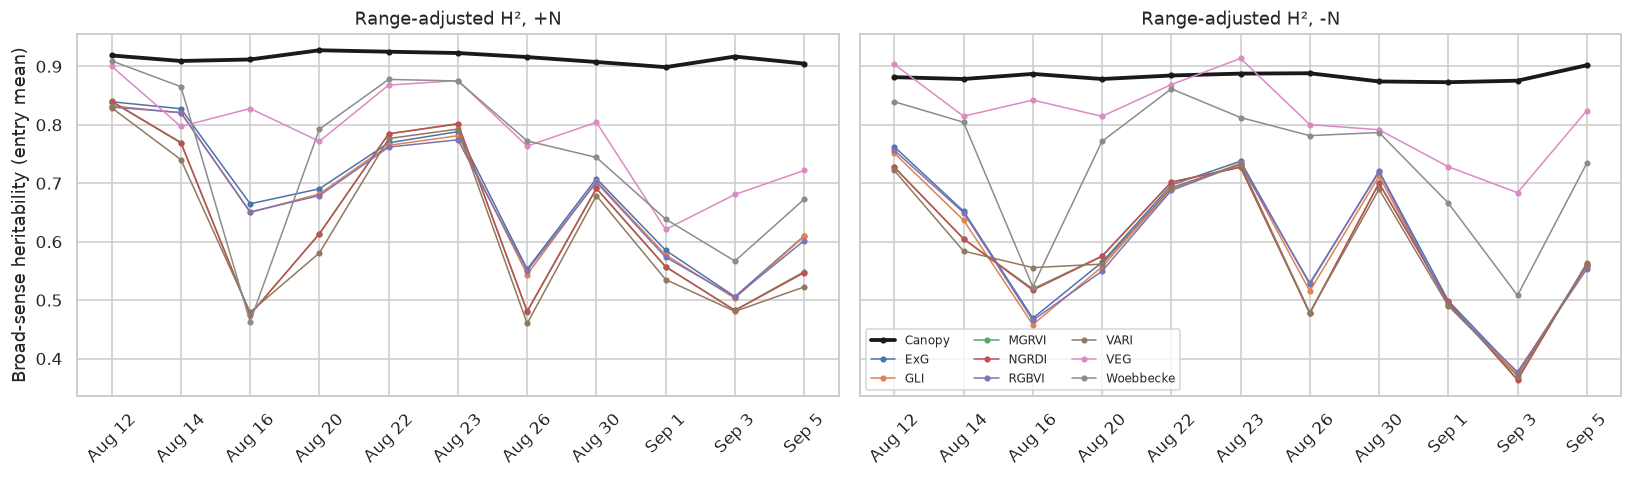

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)       # H2 over time per treatment
for ax, trt in zip(axes, TRT_COL):                                   # +N and -N panels
    piv = h2[h2.Treatment == trt].pivot(index="date", columns="trait", values="H2_range").loc[DATES]
    for tr in piv.columns:                                           # one line per trait
        ax.plot([LABEL[d] for d in DATES], piv[tr], marker="o", ms=3, lw=2.5 if tr == "Canopy" else 1,
                color="k" if tr == "Canopy" else None, label=tr)
    ax.set_title(f"Range-adjusted H², {TRT_LAB[trt]}"); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Broad-sense heritability (entry mean)"); axes[1].legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures/heritability.png"); plt.show()

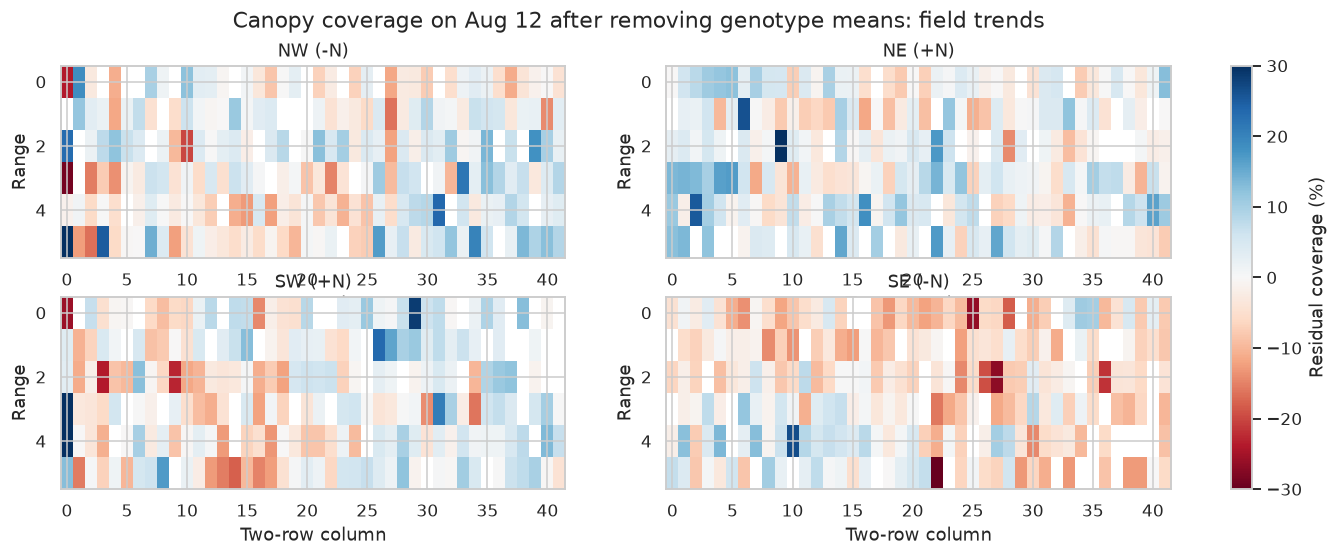

In [35]:
aug12 = cg[cg.date == "Aug12"].merge(vi[["Row", "quadrant", "fcol", "frange"]].drop_duplicates(), on="Row")
aug12["resid"] = smf.ols("Q('Percent.Cover') ~ C(Pedigree)", data=aug12).fit().resid  # remove genotype means
fig, axes = plt.subplots(2, 2, figsize=(14, 5))                      # quadrants in field position
for ax, q in zip(axes.ravel(), ["NW", "NE", "SW", "SE"]):            # NW NE top, SW SE bottom
    grid = aug12[aug12.quadrant == q].pivot_table(index="frange", columns="fcol", values="resid")  # range x col
    im = ax.imshow(grid, cmap="RdBu", vmin=-30, vmax=30, aspect="auto")   # residual map
    ax.set_title(f"{q} ({'+N' if q in ('NE', 'SW') else '-N'})"); ax.set_xlabel("Two-row column"); ax.set_ylabel("Range")
fig.colorbar(im, ax=axes, label="Residual coverage (%)", fraction=0.02)
fig.suptitle("Canopy coverage on Aug 12 after removing genotype means: field trends"); plt.show()

Canopy coverage is the most heritable image trait (H² about 0.9 on every date), followed by VEG and Woebbecke,
while ExG, GLI, NGRDI, MGRVI, RGBVI and VARI sit around 0.6. The heritability of the greenness indices drops on the
low-light flights (Aug 16, Aug 26, Sept 3) whereas canopy coverage does not: a mask is less sensitive to exposure
than a colour ratio. July 6 was flown over only one replicate per treatment, so H² is not estimable there.
Adjusting for range within quadrant raises H² only slightly; the residual maps show patchy rather than smooth
trends, so a 2D spline model (for example SpATS) would be the next step in a full analysis.

In [36]:
h2_cc = float(h2[(h2.trait == "Canopy") & (h2.date == "Aug12") & (h2.Treatment == "No Nitrogen")].H2_range.iloc[0])
print(f"Canopy coverage H2 on Aug 12 (-N), used for the simulation below: {h2_cc:.2f}")
assert 0 < h2_cc < 1                                                 # [CHECK] estimable heritability

Canopy coverage H2 on Aug 12 (-N), used for the simulation below: 0.88


## Published GWAS regions

Table S3 lists the 345 candidate regions the authors found with GEMMA: for each trait (canopy coverage and 8 VIs),
treatment and date, the region boundaries, the lead SNP and its p-value, and the number of significant SNPs. A
region was called when more than five SNPs passed p < 1.2 × 10⁻⁶ (1/n, with n = 769,690 independent SNPs from LD
pruning) within ±50 kb windows.

A single-date hit can be a false positive; a region found on several dates (independent flights) is more credible.
We merge overlapping regions of the same trait across dates and treatments (allowing a 100 kb gap) and count how
often each was detected.

In [37]:
gw = pd.read_csv(FILES["gwas"])                                      # published candidate regions
gw["date_lab"] = pd.to_datetime(gw.date + "-2019", format="%d-%b-%Y").dt.strftime("%b %-d")  # "Aug 12"
print(gw.groupby(["trait", "treatment"]).size().unstack().fillna(0).astype(int))
gw.head()

treatment  High Nitrogen  Low Nitrogen
trait                                 
Canopy                32            23
ExG                   10            12
GLI                   12            11
MGR                   12             5
NGR                   11             5
RGB                    9            12
VARI                  10             7
VEG                   15            15
Woebbecke             70            74


,trait,treatment,date,chrom,start,end,p_lead,pos_lead,n_sig_snps,date_lab
0,Canopy,High Nitrogen,1-Sep,1,280944269,281046209,6.810000e-08,280994455,19,Sep 1
1,Canopy,High Nitrogen,1-Sep,2,157015524,157115674,4.840000e-07,157065575,5,Sep 1
2,Canopy,High Nitrogen,1-Sep,5,91731758,91999510,2.200000e-07,91840746,6,Sep 1
3,Canopy,High Nitrogen,1-Sep,8,36191555,36417798,4.730000e-07,36313941,5,Sep 1
4,Canopy,High Nitrogen,12-Aug,1,83770813,83874504,1.060000e-07,83820963,11,Aug 12


In [38]:
def merge_regions(df, gap=100_000):
    """Cluster overlapping (or within `gap` bp) regions on the same chromosome; returns cluster ids."""
    df = df.sort_values(["chrom", "start"]).copy()                   # genome order
    cid, c, end, ch = [], -1, -1, None                               # running cluster state
    for r in df.itertuples():                                        # sweep along the genome
        if r.chrom != ch or r.start > end + gap:                     # new cluster
            c, end, ch = c + 1, r.end, r.chrom
        else:                                                        # extend current cluster
            end = max(end, r.end)
        cid.append(c)
    df["cluster"] = cid                                              # attach ids
    return df

loci = []                                                            # one row per recurrent locus
for trait, sub in gw.groupby("trait"):                               # merge within each trait
    m = merge_regions(sub)                                           # cluster across dates and treatments
    for cid, x in m.groupby("cluster"):                              # summarise each cluster
        loci.append({"trait": trait, "chrom": x.chrom.iloc[0], "start": x.start.min(), "end": x.end.max(),
                     "n_detections": len(x), "n_dates": x.date.nunique(),
                     "treatments": "/".join(sorted(set(x.treatment.str.split().str[0]))),
                     "best_p": x.p_lead.min(), "lead_pos": x.loc[x.p_lead.idxmin(), "pos_lead"]})
loci = pd.DataFrame(loci)                                            # all clusters
recurrent = loci[loci.n_detections >= 3].sort_values(["chrom", "start"])  # found 3+ times
print(f"{len(loci)} trait-specific loci; {len(recurrent)} detected 3 or more times (paper: 29)")
recurrent[recurrent.trait == "Canopy"]

220 trait-specific loci; 28 detected 3 or more times (paper: 29)


,trait,chrom,start,end,n_detections,n_dates,treatments,best_p,lead_pos
0,Canopy,1,83770813,83874504,5,5,High,5.230000e-08,83820963
1,Canopy,1,208869082,209142501,12,8,High/Low,2.550000e-10,209091350
2,Canopy,1,280944269,281046209,9,6,High/Low,6.810000e-08,280994455
4,Canopy,3,169434086,169650849,5,5,High,6.000000e-08,169547291
5,Canopy,4,7302181,7452920,9,6,High/Low,6.740000e-08,7356521
6,Canopy,5,32724158,32947941,3,3,Low,2.410000e-08,32778378
7,Canopy,5,91731758,92001381,3,3,High,3.930000e-08,91840746


In [39]:
rec_m = merge_regions(recurrent.assign(date="x"))                    # overlap recurrent loci across traits
multi = rec_m.groupby("cluster").trait.nunique()                     # traits per shared locus
print(f"Unique recurrent genomic regions across traits: {rec_m.cluster.nunique()}; "
      f"shared by 2+ traits: {(multi >= 2).sum()}")
hcf = loci[(loci.trait == "Canopy") & (loci.chrom == 1) & (loci.start < 209.2e6) & (loci.end > 208.8e6)]
print("Chr1 208.8-209.1 Mb canopy locus (HCF244 homolog Zm00001d031997 nearby):")
hcf[["chrom", "start", "end", "n_detections", "n_dates", "treatments", "best_p", "lead_pos"]]

Unique recurrent genomic regions across traits: 25; shared by 2+ traits: 2
Chr1 208.8-209.1 Mb canopy locus (HCF244 homolog Zm00001d031997 nearby):


,chrom,start,end,n_detections,n_dates,treatments,best_p,lead_pos
1,1,208869082,209142501,12,8,High/Low,2.550000e-10,209091350


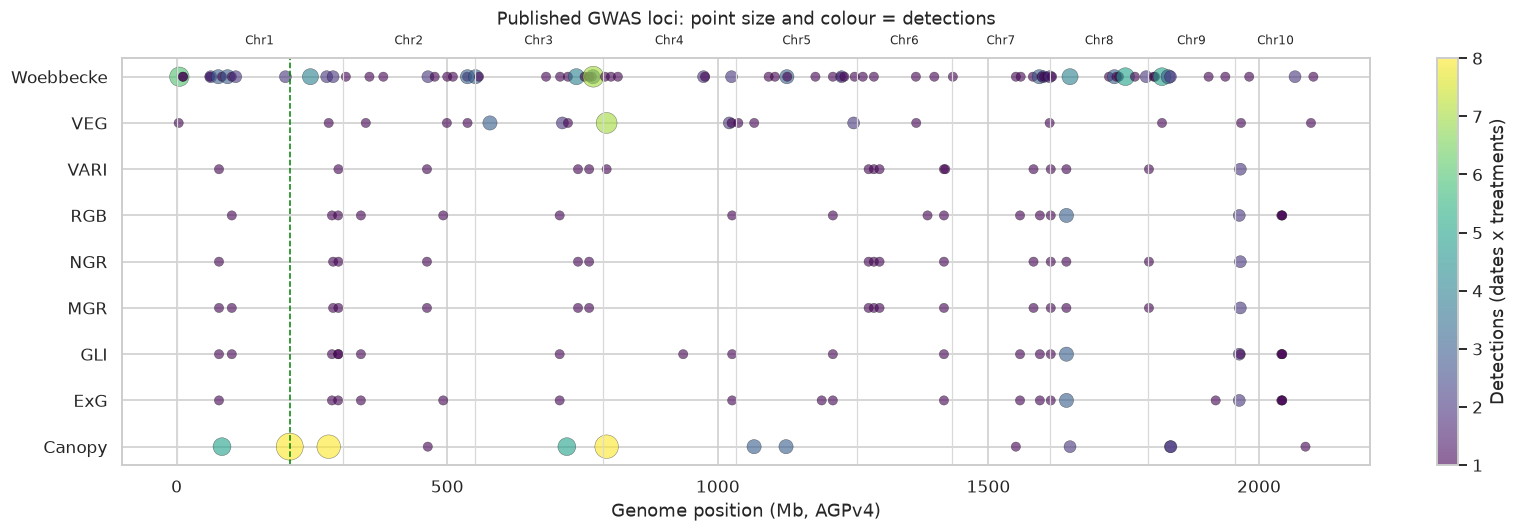

In [40]:
CHR_LEN = {1: 307041717, 2: 244442276, 3: 235667834, 4: 246994605, 5: 223902240,
           6: 174033170, 7: 182381542, 8: 181122637, 9: 159769782, 10: 150982314}  # B73 AGPv4 (bp)
offset = dict(zip(CHR_LEN, np.cumsum([0] + list(CHR_LEN.values())[:-1])))  # cumulative genome position
loci["gpos"] = loci.chrom.map(offset) + (loci.start + loci.end) / 2  # midpoint on the genome axis
TR_ORDER = ["Canopy", "ExG", "GLI", "MGR", "NGR", "RGB", "VARI", "VEG", "Woebbecke"]  # y-axis order
fig, ax = plt.subplots(figsize=(14, 5))                              # Figure 5A style
for i, tr in enumerate(TR_ORDER):                                    # one track per trait
    s = loci[loci.trait == tr]
    ax.scatter(s.gpos / 1e6, np.full(len(s), i), s=12 + 25 * s.n_detections, alpha=0.6,
               c=s.n_detections, cmap="viridis", vmin=1, vmax=8, edgecolor="k", lw=0.3)
for c, o in offset.items():                                          # chromosome boundaries
    ax.axvline(o / 1e6, color="0.85", lw=0.8)
    ax.text((o + CHR_LEN[c] / 2) / 1e6, len(TR_ORDER) - 0.3, f"Chr{c}", ha="center", fontsize=8)
ax.axvline((offset[1] + 209e6) / 1e6, color="green", ls="--", lw=1)  # HCF244 locus
ax.set_yticks(range(len(TR_ORDER))); ax.set_yticklabels(TR_ORDER)
ax.set_xlabel("Genome position (Mb, AGPv4)"); ax.set_title("Published GWAS loci: point size and colour = detections", pad=22)
plt.colorbar(ax.collections[0], ax=ax, label="Detections (dates x treatments)", fraction=0.02)
plt.tight_layout(); plt.savefig(OUT / "figures/fig5a_gwas_loci.png"); plt.show()

With our merge rule we recover 28 trait-specific loci detected three or more times (the paper reports 29; the exact
window and counting rule of the paper is not fully specified). The canopy-coverage locus on chromosome 1 near
209.0 Mb is the most recurrent signal, detected on 8 dates and under both N conditions, consistent with the paper's
candidate gene *Zm00001d031997* (HCF244, photosystem II assembly) 4.6 kb from the lead SNP. Woebbecke contributes the most
regions overall and also most of the recurrent ones (16 of 28), followed by canopy coverage (7), both among the most
heritable image traits in the previous section.

## GWAS and genomic prediction methods [SIMULATED]

Before touching real genotypes it pays to run the methods where the answer is known. This section simulates
markers and a trait with planted QTL, so we can check that the mixed model removes structure-driven inflation, that
peak calling recovers true QTL, and how accurate GBLUP can be. The next two sections run the same models on the real
HapMap3 genotypes.

The simulation is built to look like a maize diversity panel:

* three subpopulations (think stiff stalk, non-stiff stalk, tropical) with F_ST ≈ 0.1 (Balding-Nichols model);
* 10 chromosomes with the AGPv4 lengths and 1,500 SNPs each, with linkage disequilibrium created by copying 8
  founder haplotypes per subpopulation in tracts of about 5 Mb;
* inbred lines, so each line carries two identical haplotypes (dosage 0 or 2);
* a trait with H² equal to the canopy-coverage heritability estimated above, controlled by 12 major QTL (one of
  them placed at chromosome 1, 209.09 Mb), 300 small-effect loci and a subpopulation mean shift that creates
  confounding.

**Steps**, as in the outline: marker QC (call rate, MAF), kinship (VanRaden), PCA, a mixed-model GWAS that
mirrors GEMMA (y = Xβ + gα + u + ε, u ~ N(0, Kσ²_g)), genomic inflation, peak calling, and GBLUP with
cross-validation.

In [41]:
lines = sorted(fb.loc[fb.Genotype != "Check", "Genotype"].unique())  # the real 233 inbred names
n, n_chr, m_chr = len(lines), 10, 1500                               # lines, chromosomes, SNPs per chromosome
pop = rng.choice(3, size=n, p=[0.35, 0.35, 0.30])                    # subpopulation of each line
snp_rows, hap_blocks = [], []                                        # SNP map and genotype blocks
for c in range(1, n_chr + 1):                                        # chromosome by chromosome
    pos = np.sort(rng.choice(CHR_LEN[c], m_chr, replace=False))      # SNP positions (bp)
    p_anc = rng.uniform(0.05, 0.95, m_chr)                           # ancestral allele frequency
    fst = 0.1                                                        # population differentiation
    a, b = p_anc * (1 - fst) / fst, (1 - p_anc) * (1 - fst) / fst   # Balding-Nichols beta parameters
    p_pop = rng.beta(a, b, size=(3, m_chr))                          # frequency in each subpopulation
    fresh = (rng.random((3, 8, m_chr)) < p_pop[:, None, :]).astype(np.int8)  # independent founder alleles
    founders = fresh.copy()                                          # 8 founder haplotypes per subpopulation
    keep_prev = rng.random((3, 8, m_chr)) < 0.85                     # founder LD: neighbours often share state
    for j in range(1, m_chr):                                        # walk along the founder haplotypes
        founders[:, :, j] = np.where(keep_prev[:, :, j], founders[:, :, j - 1], fresh[:, :, j])
    gap = np.diff(pos, prepend=pos[0]) / 1e6                         # Mb between consecutive SNPs
    switch = rng.random((n, m_chr)) < (1 - np.exp(-gap / 5.0))       # recombination, ~5 Mb mean tract
    which = np.zeros((n, m_chr), dtype=int)                          # founder copied at each SNP
    which[:, 0] = rng.integers(0, 8, n)                              # first founder
    for j in range(1, m_chr):                                        # Markov walk along the chromosome
        which[:, j] = np.where(switch[:, j], rng.integers(0, 8, n), which[:, j - 1])
    hap = founders[pop[:, None], which, np.arange(m_chr)[None, :]]   # copied alleles
    hap_blocks.append(2 * hap)                                       # inbred: dosage 0 or 2
    snp_rows.append(pd.DataFrame({"chrom": c, "pos": pos}))
geno = pd.DataFrame(np.hstack(hap_blocks), index=lines).astype(float)  # lines x SNPs dosage matrix
snp_map = pd.concat(snp_rows, ignore_index=True)                     # SNP map
snp_map["snp"] = [f"S{c}_{p}" for c, p in zip(snp_map.chrom, snp_map.pos)]  # SNP ids
geno.columns = snp_map.snp                                           # label columns
geno = geno.mask(rng.random(geno.shape) < 0.02)                      # 2% missing calls
print(f"[SIMULATED] genotype matrix: {geno.shape[0]} lines x {geno.shape[1]:,} SNPs")

[SIMULATED] genotype matrix: 233 lines x 15,000 SNPs


QC: 14,995 of 15,000 SNPs kept (MAF > 0.05, call rate >= 0.9)


Variance explained by PCs 1-5: [5.3 4.4 0.7 0.7 0.7]


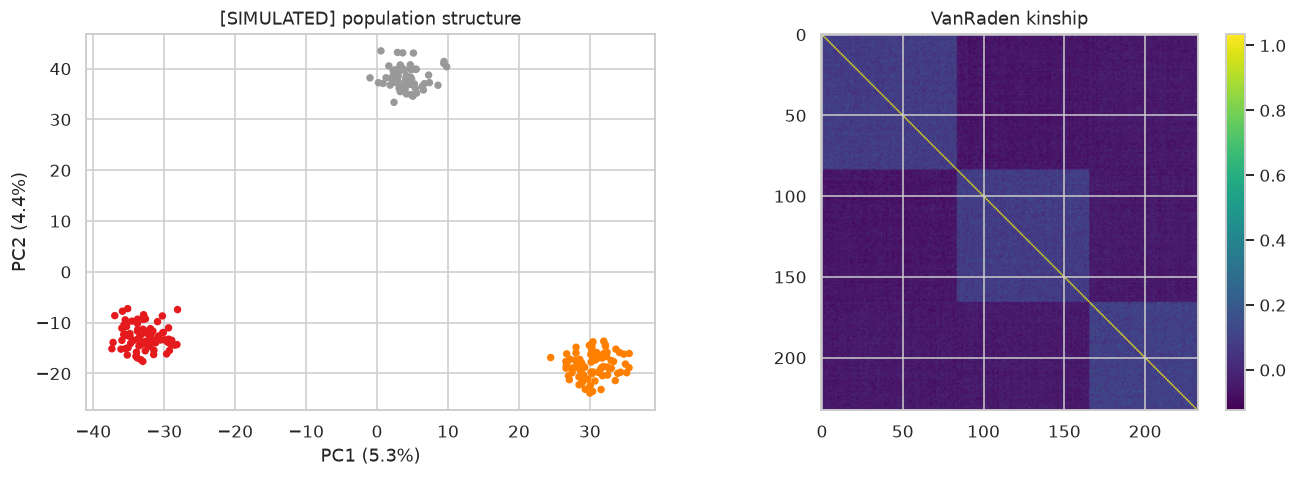

In [42]:
call = geno.notna().mean()                                           # SNP call rate
p_alt = geno.mean() / 2                                              # allele frequency
maf = np.minimum(p_alt, 1 - p_alt)                                   # minor allele frequency
keep = (call >= 0.9) & (maf > 0.05)                                  # QC: call rate >= 90%, MAF > 5%
G = geno.loc[:, keep].apply(lambda s: s.fillna(s.mean()))            # mean-impute remaining gaps
smap = snp_map[keep.values].reset_index(drop=True)                   # map of retained SNPs
print(f"QC: {keep.sum():,} of {len(keep):,} SNPs kept (MAF > 0.05, call rate >= 0.9)")

M = G.to_numpy()                                                     # dosage matrix
pf = M.mean(0) / 2                                                   # allele frequencies
Z = M - 2 * pf                                                       # centred dosages
K = Z @ Z.T / (2 * np.sum(pf * (1 - pf)))                            # VanRaden (2008) kinship
K = K / np.mean(np.diag(K))                                          # scale mean diagonal to 1 (inbreds give ~2)
pca = PCA(n_components=5, random_state=SEED).fit(Z)                  # population structure
pcs = pca.transform(Z)                                               # PC scores
print("Variance explained by PCs 1-5:", (100 * pca.explained_variance_ratio_).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                    # structure and kinship
axes[0].scatter(pcs[:, 0], pcs[:, 1], c=pop, cmap="Set1", s=15)      # PCs coloured by subpopulation
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
            title="[SIMULATED] population structure")
order = np.argsort(pop)                                              # group lines by subpopulation
im = axes[1].imshow(K[np.ix_(order, order)], cmap="viridis"); axes[1].set_title("VanRaden kinship")
plt.colorbar(im, ax=axes[1], fraction=0.046); plt.tight_layout(); plt.show()

In [43]:
n_qtl = 12                                                           # number of causal loci
qtl_idx = list(rng.choice(len(smap), n_qtl - 1, replace=False))      # random QTL
chr1 = smap.index[(smap.chrom == 1)]                                 # chromosome 1 SNPs
qtl_idx.append(int(chr1[np.argmin(np.abs(smap.loc[chr1, "pos"] - 209_091_350))]))  # QTL at Chr1 209.09 Mb
eff = rng.normal(0, 1, n_qtl); eff[-1] = 2.5                         # effects; the Chr1 QTL is large
poly = rng.choice(len(smap), 300, replace=False)                     # polygenic background loci
gval = (Z[:, qtl_idx] @ eff + Z[:, poly] @ rng.normal(0, 0.15, 300)  # major QTL + many small effects
        + 0.6 * (pop == 2))                                          # subpopulation shift (confounding)
h2_sim = h2_cc                                                       # heritability from the real data
noise = rng.normal(0, np.sqrt(gval.var() * (1 - h2_sim) / h2_sim), n)  # residual for the target H2
y_sim = 50 + 5 * (gval - gval.mean()) / gval.std() + noise * 5 / gval.std()  # coverage-like scale (%)
print(f"[SIMULATED] trait: mean {y_sim.mean():.1f}%, sd {y_sim.std():.1f}%, target H2 {h2_sim:.2f}, "
      f"QTL at Chr1 {smap.loc[qtl_idx[-1], 'pos'] / 1e6:.2f} Mb")

[SIMULATED] trait: mean 50.1%, sd 5.3%, target H2 0.88, QTL at Chr1 209.01 Mb


**Mixed-model GWAS.** Following EMMAX/GEMMA, we first estimate the variance ratio δ = σ²_e/σ²_g once under the null
model by restricted maximum likelihood, using the eigen-decomposition K = U S Uᵀ. Rotating by Uᵀ and weighting by
1/√(S + δ) turns the correlated model into ordinary least squares, after which every SNP test is a fast vectorised
regression with the first three PCs as fixed covariates. The paper's threshold is 1/n_eff, where n_eff counts
independent SNPs after LD pruning; we estimate n_eff the same way with greedy pruning (r² ≥ 0.1 within 50-SNP
windows).

In [44]:
def reml_delta(y, X, S, U, grid=np.logspace(-3, 3, 121)):
    """REML estimate of delta = sigma_e^2 / sigma_g^2 by grid search over the null mixed model."""
    yt, Xt = U.T @ y, U.T @ X                                        # rotate to independent components
    best, best_ll = None, -np.inf                                    # track the best delta
    for d in grid:                                                   # profile restricted likelihood
        w = 1 / (S + d)                                              # component weights
        XtW = Xt.T * w                                               # X' W
        beta = np.linalg.solve(XtW @ Xt, XtW @ yt)                   # GLS fixed effects
        r = yt - Xt @ beta                                           # residuals
        s2 = np.sum(w * r**2) / (len(y) - X.shape[1])                # residual variance
        ll = -0.5 * (np.sum(np.log(S + d)) + np.linalg.slogdet(XtW @ Xt)[1] + (len(y) - X.shape[1]) * np.log(s2))
        if ll > best_ll:                                             # keep the maximum
            best, best_ll = d, ll
    return best

def mlm_gwas(y, M, K, covars):
    """EMMAX-style mixed-model scan: returns beta, se and p-value for each SNP column of M."""
    S, U = np.linalg.eigh(K)                                         # K = U diag(S) U'
    S = np.clip(S, 1e-8, None)                                       # numerical safety
    X = np.column_stack([np.ones(len(y)), covars])                   # intercept + PCs
    delta = reml_delta(y, X, S, U)                                   # variance ratio under the null
    w = 1 / np.sqrt(S + delta)                                       # whitening weights
    yt, Xt, Mt = w * (U.T @ y), w[:, None] * (U.T @ X), w[:, None] * (U.T @ M)  # whitened data
    P = np.eye(len(y)) - Xt @ np.linalg.pinv(Xt)                     # residual-maker for covariates
    yr, Mr = P @ yt, P @ Mt                                          # covariate-adjusted
    ss = np.sum(Mr**2, axis=0)                                       # SNP sums of squares
    beta = Mr.T @ yr / ss                                            # SNP effects
    dof = len(y) - X.shape[1] - 1                                    # residual degrees of freedom
    rss = np.sum(yr**2) - beta**2 * ss                               # residual sum of squares per SNP
    se = np.sqrt(rss / dof / ss)                                     # standard errors
    p = 2 * stats.t.sf(np.abs(beta / se), dof)                       # two-sided p-values
    return pd.DataFrame({"beta": beta, "se": se, "p": p}), 1 / delta  # results and sigma_g^2/sigma_e^2

def n_independent(M, chroms, window=50, r2=0.1):
    """Count SNPs left after greedy LD pruning within sliding windows, chromosome by chromosome."""
    total = 0                                                        # running count
    for c in np.unique(chroms):                                      # each chromosome
        X = M[:, chroms == c]                                        # SNPs on this chromosome
        X = (X - X.mean(0)) / (X.std(0) + 1e-12)                     # standardise for correlations
        kept = []                                                    # retained SNP indices
        for j in range(X.shape[1]):                                  # in map order
            recent = [k for k in kept[-window:]]                     # previous kept SNPs in window
            if not recent or np.max((X[:, recent].T @ X[:, j] / len(X)) ** 2) < r2:
                kept.append(j)                                       # independent enough: keep
        total += len(kept)
    return total

res, gratio = mlm_gwas(y_sim, M, K, pcs[:, :3])                      # MLM with 3 PCs + kinship
res = pd.concat([smap, res], axis=1)                                 # attach the map
n_eff = n_independent(M, smap.chrom.to_numpy())                      # independent SNPs
thr = 1 / n_eff                                                      # paper's 1/n threshold
naive = mlm_gwas(y_sim, M, np.eye(n) * 1e-6 + 1e-9, np.empty((n, 0)))[0]  # GLM: no PCs, no kinship
lam = lambda p: np.median(chi2.isf(p, 1)) / chi2.ppf(0.5, 1)         # genomic inflation factor
print(f"n_eff = {n_eff:,} independent SNPs -> threshold p < {thr:.1e}")
print(f"lambda_GC: naive GLM {lam(naive.p):.2f}, MLM (K + 3 PCs) {lam(res.p):.2f}")
res.to_csv(OUT / "tables/gwas_simulated.csv", index=False)           # export

n_eff = 2,130 independent SNPs -> threshold p < 4.7e-04
lambda_GC: naive GLM 2.76, MLM (K + 3 PCs) 0.94


In [45]:
def call_peaks(res, thr, flank=1_000_000, min_snps=3):
    """Merge significant SNPs within +/- flank bp into regions and keep regions with >= min_snps SNPs."""
    sig = res[res.p < thr].assign(start=lambda d: d.pos - flank, end=lambda d: d.pos + flank)  # SNP windows
    if sig.empty:                                                    # nothing significant
        return sig
    reg = merge_regions(sig.assign(date="sim"), gap=0)               # overlap merge (from the GWAS section)
    out = reg.groupby("cluster").agg(chrom=("chrom", "first"), start=("pos", "min"), end=("pos", "max"),
                                     n_sig=("p", "size"), lead_p=("p", "min"))  # region summary
    return out[out.n_sig >= min_snps]

peaks = call_peaks(res, thr)                                         # candidate regions
qtl_tab = smap.loc[qtl_idx, ["chrom", "pos"]].assign(effect=np.abs(eff))  # true QTL
qtl_tab["found"] = [((peaks.chrom == c) & (peaks.start - 1e6 <= p) & (peaks.end + 1e6 >= p)).any()
                    for c, p in zip(qtl_tab.chrom, qtl_tab.pos)]     # QTL inside a called region?
print(f"{len(peaks)} regions called; {qtl_tab.found.sum()} of {n_qtl} true QTL recovered; "
      f"false regions: {sum(not ((qtl_tab.chrom == r.chrom) & (qtl_tab.pos.between(r.start - 1e6, r.end + 1e6))).any() for r in peaks.itertuples())}")
peaks

2 regions called; 2 of 12 true QTL recovered; false regions: 0


,chrom,start,end,n_sig,lead_p
cluster,,,,,
2,1,162993127,163831168,6,1.365333e-10
4,1,208565285,209788459,8,8.171019e-14


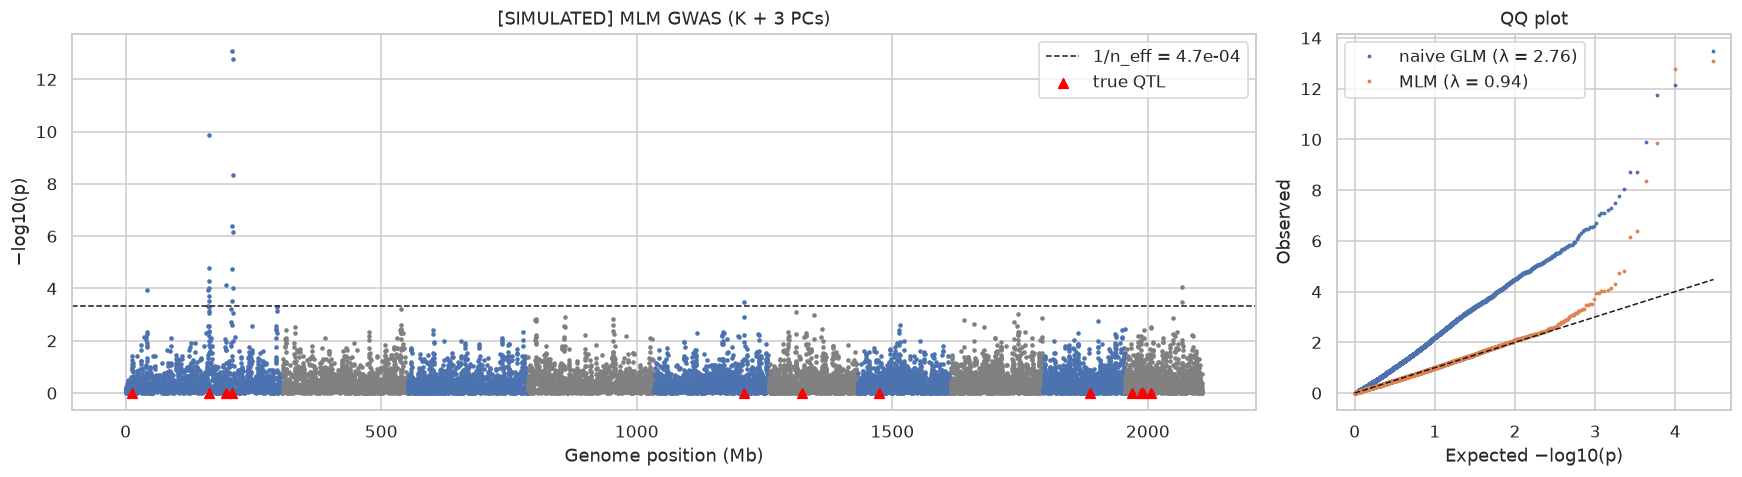

In [46]:
res["gpos"] = res.chrom.map(offset) + res.pos                        # genome-wide coordinate
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
for c in CHR_LEN:                                                    # alternate chromosome colours
    s = res[res.chrom == c]
    axes[0].scatter(s.gpos / 1e6, -np.log10(s.p), s=4, color="C0" if c % 2 else "0.5")
axes[0].axhline(-np.log10(thr), color="k", ls="--", lw=1, label=f"1/n_eff = {thr:.1e}")  # threshold
axes[0].scatter((qtl_tab.chrom.map(offset) + qtl_tab.pos) / 1e6, np.zeros(n_qtl), marker="^", color="red",
                s=40, label="true QTL")                              # where the QTL really are
axes[0].set(xlabel="Genome position (Mb)", ylabel="−log10(p)", title="[SIMULATED] MLM GWAS (K + 3 PCs)")
axes[0].legend(loc="upper right")
exp = -np.log10((np.arange(1, len(res) + 1) - 0.5) / len(res))       # expected uniform quantiles
for p, lab in [(naive.p, "naive GLM"), (res.p, "MLM")]:              # QQ plots
    axes[1].plot(exp, -np.log10(np.sort(p)), ".", ms=3, label=f"{lab} (λ = {lam(p):.2f})")
axes[1].plot([0, exp.max()], [0, exp.max()], "k--", lw=1); axes[1].set(xlabel="Expected −log10(p)",
                                                                       ylabel="Observed", title="QQ plot")
axes[1].legend(); plt.tight_layout(); plt.savefig(OUT / "figures/gwas_simulated.png"); plt.show()

The naive regression is inflated (λ > 1) because the subpopulation shift is confounded with allele frequencies;
kinship plus PCs bring λ close to 1. The large Chr1 QTL stands out, smaller QTL may fall below the threshold: with
about 230 lines, GWAS has power only for moderate-to-large effects, which is why replicated detections across dates are so
valuable. The peak rule here (±1 Mb, ≥ 3 SNPs) is scaled to our sparse 15,000-SNP panel; the paper used ±50 kb and
more than 5 SNPs on 21 million SNPs.

**Genomic prediction (GBLUP).** Instead of testing SNPs one at a time, GBLUP predicts each line's genetic value from
its relatedness to all training lines: û = σ²_g K_test,train (σ²_g K_train + σ²_e I)⁻¹ (y_train − μ). We compare it with
ridge regression on markers (rrBLUP; equivalent in theory) in 5-fold cross-validation. Accuracy is the correlation
between predicted and observed values and cannot exceed √H² on average.

[SIMULATED] accuracy: GBLUP r = 0.43 (95% CI 0.32 to 0.53), ridge r = 0.42; sqrt(H2) = 0.94


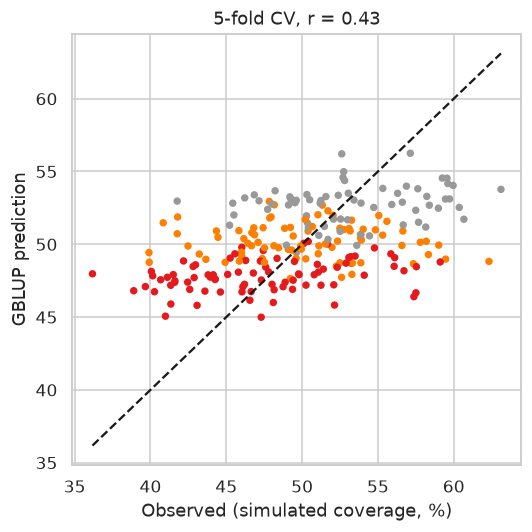

124

In [47]:
def gblup_cv(y, K, folds=5, seed=SEED):
    """Five-fold cross-validated GBLUP predictions with REML variance ratio from each training set."""
    pred = np.full(len(y), np.nan)                                   # out-of-fold predictions
    for tr, te in KFold(folds, shuffle=True, random_state=seed).split(y):  # folds
        Ktr = K[np.ix_(tr, tr)]                                      # training kinship
        S, U = np.linalg.eigh(Ktr)                                   # eigen-decomposition
        d = reml_delta(y[tr], np.ones((len(tr), 1)), np.clip(S, 1e-8, None), U)  # sigma_e2 / sigma_g2
        mu = y[tr].mean()                                            # fixed intercept
        alpha = np.linalg.solve(Ktr + d * np.eye(len(tr)), y[tr] - mu)  # (K + delta I)^-1 (y - mu)
        pred[te] = mu + K[np.ix_(te, tr)] @ alpha                    # BLUP of test lines
    return pred

pred_gblup = gblup_cv(y_sim, K)                                      # GBLUP predictions
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 5, 30)))  # rrBLUP-like ridge
pred_ridge = cross_val_predict(ridge, M, y_sim, cv=KFold(5, shuffle=True, random_state=SEED))  # same folds
acc = {"GBLUP": stats.pearsonr(y_sim, pred_gblup)[0], "Ridge (rrBLUP)": stats.pearsonr(y_sim, pred_ridge)[0]}
boot = [stats.pearsonr(y_sim[i], pred_gblup[i])[0] for i in (rng.integers(0, n, n) for _ in range(500))]  # bootstrap
print(f"[SIMULATED] accuracy: GBLUP r = {acc['GBLUP']:.2f} (95% CI {np.percentile(boot, 2.5):.2f}"
      f" to {np.percentile(boot, 97.5):.2f}), ridge r = {acc['Ridge (rrBLUP)']:.2f}; sqrt(H2) = {np.sqrt(h2_sim):.2f}")
fig, ax = plt.subplots(figsize=(5, 5))                               # predicted vs observed
ax.scatter(y_sim, pred_gblup, c=pop, cmap="Set1", s=15); ax.plot([y_sim.min(), y_sim.max()], [y_sim.min(), y_sim.max()], "k--")
ax.set(xlabel="Observed (simulated coverage, %)", ylabel="GBLUP prediction", title=f"5-fold CV, r = {acc['GBLUP']:.2f}")
plt.tight_layout(); plt.show()
(OUT / "tables/genomic_prediction_metrics.json").write_text(json.dumps(                       # export metrics
    {"simulated": True, "h2": h2_sim, "folds": 5, "seed": SEED, **{k: round(v, 3) for k, v in acc.items()}}, indent=2))

**[CHECK]** The MLM removes inflation (λ_GC below the naive value and near 1), the Chr1 QTL is detected and the
prediction accuracy is plausible: positive and below √H² + a margin for sampling noise.

In [48]:
assert lam(res.p) < lam(naive.p) and lam(res.p) < 1.2                # [CHECK] structure controlled
assert qtl_tab.found.iloc[-1]                                        # [CHECK] the Chr1 QTL is recovered
assert 0 < acc["GBLUP"] < np.sqrt(h2_sim) + 0.15                     # [CHECK] plausible accuracy

## GWAS on real HapMap3 genotypes

Now the same mixed-model GWAS on real markers. The genotypes are the HapMap 3.2.1 calls for the maize 282
association panel (Bukowski et al. 2018; whole-genome sequencing at about 7x, AGPv4 coordinates, not imputed), from
the public MaizeGDB/Panzea Box share. The scan runs **outside the notebook** with two scripts in
`maize_uav_htp/genotypes/` because it reads 32 GB of VCFs and tests 14 million SNPs 24 times:

| Step | Script | What it does |
|---|---|---|
| Download and filter | `01_download_filter.sh` | Streams each chromosome VCF (32.4 GB in total), keeps our lines, biallelic SNPs, MAF > 0.05 and call rate ≥ 0.8 with PLINK 2, writes a compact PLINK fileset and deletes the raw VCF |
| Association | `02_gwas.py` | Merges chromosomes; LD pruning (10 kb window, r² ≥ 0.1) to count independent SNPs; 3 PCs; centred kinship and one LMM Wald test per trait with GEMMA 0.98.5; keeps SNPs with p < 10⁻³, a 0.5% random background, λ_GC and candidate regions |

The traits are the genotype means (over the two replicates) of reference-replicate canopy coverage (ExG 131) on each
of the 12 dates under +N and −N: 24 scans. The model is the paper's: y = Wα + xβ + u + ε with the intercept and 3
PCs in W and u ~ N(0, Kσ²_g). The significance threshold is the paper's 1/n, with n the number of LD-pruned
independent SNPs, and a region is called when more than five significant SNPs fall within merged ±50 kb windows.

Differences from the paper to keep in mind: we genotype 214 of the 233 lines (19 field names have no sequenced
sample in the 282 set), and the extra call-rate filter leaves about 14 million SNPs instead of 21 million.

In [49]:
GENO = DATA / "genotypes"                                            # real-genotype GWAS folder
RES_G = GENO / "results"                                             # outputs of 02_gwas.py
RUN_GWAS = False                                                     # True reruns the pipeline (hours, 32 GB download)
if RUN_GWAS:                                                         # optional full rerun
    import subprocess                                                # run the two pipeline scripts
    subprocess.run(["bash", "01_download_filter.sh"], cwd=GENO, check=True)
    subprocess.run([sys.executable, "02_gwas.py"], cwd=GENO, check=True)

gmeta = json.loads((RES_G / "gwas_meta.json").read_text())           # panel and threshold
idmap = pd.read_csv(GENO / "genotype_to_vcf_id.csv")                 # field name to VCF sample
print(f"Lines genotyped: {gmeta['n_lines']} of {len(idmap)} "
      f"({idmap.match.value_counts().to_dict()}); phenotyped and genotyped: {gmeta['n_lines_phenotyped']}")
print(f"SNPs tested: {gmeta['n_snps']:,}; independent after LD pruning: {gmeta['n_independent']:,} "
      f"-> threshold p < {gmeta['threshold']:.1e} (paper: 769,690 -> 1.2e-06)")

Lines genotyped: 214 of 233 ({'exact': 198, 'none': 19, 'case': 8, 'alias': 8}); phenotyped and genotyped: 214
SNPs tested: 14,007,199; independent after LD pruning: 459,162 -> threshold p < 2.2e-06 (paper: 769,690 -> 1.2e-06)


In [50]:
gsum = pd.read_csv(RES_G / "gwas_summary.csv")                       # one row per scan
gsum[["trt", "date"]] = gsum.trait.str.extract(r"CC_(PN|MN)_(\w+)")  # treatment and date from the trait name
gsum["N level"] = gsum.trt.map({"PN": "+N", "MN": "-N"})              # readable treatment
gsum_tab = (gsum.pivot(index="date", columns="N level", values=["lambda_gc", "n_sig", "n_regions"])  # date x trt
              .reindex(DATES).round(3))
gsum_tab                                                             # inflation, hits and regions per scan

lambda_gc         n_sig       n_regions     
N level        +N     -N     +N    -N        +N   -N
date                                                
July6       1.023  1.057   33.0  15.0       1.0  0.0
Aug12       1.028  1.036   72.0  79.0       2.0  2.0
Aug14       1.027  1.033   28.0  64.0       1.0  2.0
Aug16       1.030  1.030   23.0  63.0       1.0  2.0
Aug20       1.034  1.036   22.0  65.0       1.0  2.0
Aug22       1.021  1.021   31.0  63.0       1.0  2.0
Aug23       1.027  1.026  205.0  72.0       3.0  2.0
Aug26       1.019  1.023   96.0  77.0       4.0  3.0
Aug30       1.024  1.023   45.0  69.0       1.0  2.0
Sept1       1.018  1.020   31.0  52.0       1.0  2.0
Sept3       1.026  1.019   30.0  45.0       1.0  1.0
Sept5       1.021  1.017   24.0  23.0       1.0  0.0

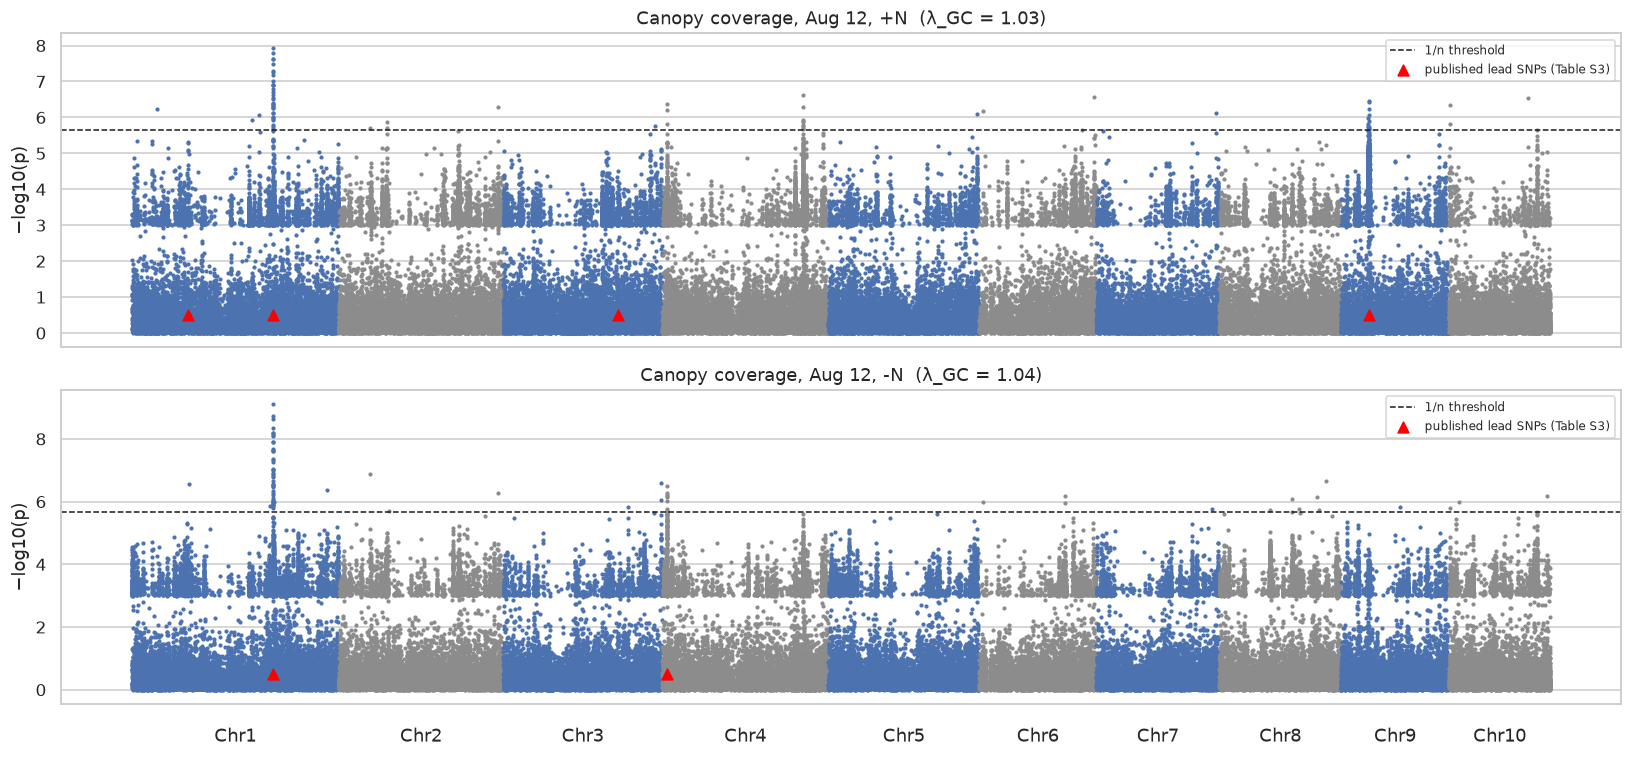

In [51]:
def load_top(trait):
    """SNPs with p < 1e-3 plus a 0.5% random background for one real-GWAS trait."""
    t = pd.read_parquet(RES_G / f"{trait}.top.parquet")              # reduced GEMMA output
    t["gpos"] = t.chr.map(offset) + t.ps                             # genome-wide coordinate
    return t

pub_cc = gw[gw.trait == "Canopy"]                                    # published canopy regions (Table S3)
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)         # Manhattan plots for Aug 12
for ax, (trait, lab) in zip(axes, [("CC_PN_Aug12", "+N"), ("CC_MN_Aug12", "-N")]):
    t = load_top(trait)                                              # one scan
    for c in CHR_LEN:                                                # alternate chromosome colours
        s = t[t.chr == c]
        ax.scatter(s.gpos / 1e6, -np.log10(s.p_wald), s=3, color="C0" if c % 2 else "0.55", rasterized=True)
    ax.axhline(-np.log10(gmeta["threshold"]), color="k", ls="--", lw=1, label="1/n threshold")  # paper's threshold
    pub = pub_cc[(pub_cc.date == "12-Aug") & (pub_cc.treatment.str.startswith("High" if lab == "+N" else "Low"))]
    ax.scatter((pub.chrom.map(offset) + pub.pos_lead) / 1e6, np.full(len(pub), 0.5), marker="^", color="red",
               s=50, label="published lead SNPs (Table S3)")       # paper's peaks for the same scan
    ax.set(ylabel="−log10(p)", title=f"Canopy coverage, Aug 12, {lab}  (λ_GC = "
           f"{gsum.set_index('trait').loc[trait, 'lambda_gc']:.2f})"); ax.legend(loc="upper right", fontsize=8)
for c, o in offset.items():                                          # chromosome labels
    axes[1].text((o + CHR_LEN[c] / 2) / 1e6, -0.12, f"Chr{c}", ha="center", transform=axes[1].get_xaxis_transform())
axes[1].set_xticks([]); plt.tight_layout(); plt.savefig(OUT / "figures/gwas_real_manhattan_aug12.png"); plt.show()

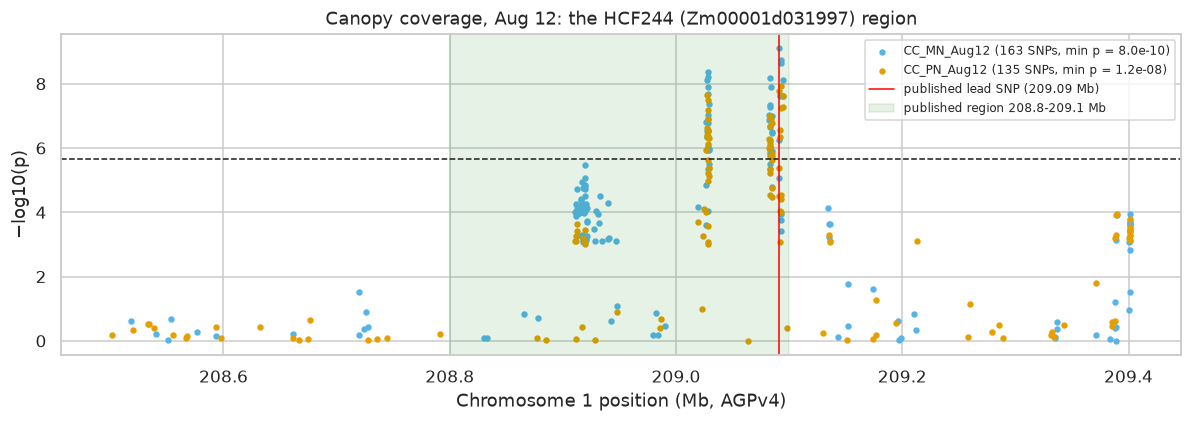

In [52]:
fig, ax = plt.subplots(figsize=(11, 4))                              # zoom on the HCF244 region (Figure 5B)
for trait, c in [("CC_MN_Aug12", TRT_COL["No Nitrogen"]), ("CC_PN_Aug12", TRT_COL["Nitrogen"])]:
    t = load_top(trait)                                              # one scan
    z = t[(t.chr == 1) & t.ps.between(208.5e6, 209.5e6)]             # 1 Mb window
    ax.scatter(z.ps / 1e6, -np.log10(z.p_wald), s=10, color=c, label=f"{trait} ({len(z)} SNPs, min p = "
               f"{z.p_wald.min():.1e})")
ax.axhline(-np.log10(gmeta["threshold"]), color="k", ls="--", lw=1)  # threshold
ax.axvline(209_091_350 / 1e6, color="red", lw=1, label="published lead SNP (209.09 Mb)")  # paper's lead SNP
ax.axvspan(208.8, 209.1, color="green", alpha=0.1, label="published region 208.8-209.1 Mb")
ax.set(xlabel="Chromosome 1 position (Mb, AGPv4)", ylabel="−log10(p)",
       title="Canopy coverage, Aug 12: the HCF244 (Zm00001d031997) region")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / "figures/gwas_real_chr1_zoom.png"); plt.show()

In [53]:
greg = pd.read_csv(RES_G / "gwas_regions.csv")                       # candidate regions of all 24 scans
greg[["trt", "date"]] = greg.trait.str.extract(r"CC_(PN|MN)_(\w+)") # treatment and date
greg["treatment"] = greg.trt.map({"PN": "High", "MN": "Low"})        # same labels as Table S3
ours = merge_regions(greg.assign(trait="Canopy"))                    # merge across dates and treatments
loc_ours = (ours.groupby("cluster")                                  # one row per real-GWAS locus
               .agg(chrom=("chrom", "first"), start=("start", "min"), end=("end", "max"),
                    n_detections=("date", "size"), n_dates=("date", "nunique"),
                    treatments=("treatment", lambda s: "/".join(sorted(set(s)))), best_p=("p_lead", "min"))
               .reset_index(drop=True))
pub_loci = loci[loci.trait == "Canopy"]                              # published canopy loci (merged above)

def overlaps(row, table, gap=100_000):
    """True when a locus overlaps (within `gap` bp) any locus of another table."""
    t = table[table.chrom == row.chrom]                              # same chromosome
    return bool(((t.start - gap <= row.end) & (t.end + gap >= row.start)).any())

loc_ours["in_paper"] = loc_ours.apply(overlaps, axis=1, table=pub_loci)          # replicated published locus?
pub_loci = pub_loci.assign(found_here=pub_loci.apply(overlaps, axis=1, table=loc_ours))  # recovered by us?
print(f"Real GWAS: {len(greg)} region calls in 24 scans -> {len(loc_ours)} loci; "
      f"{(loc_ours.n_detections >= 3).sum()} detected 3+ times")
print(f"Published canopy loci recovered: {pub_loci.found_here.sum()} of {len(pub_loci)}; "
      f"recurrent (3+) published loci recovered: {pub_loci[pub_loci.n_detections >= 3].found_here.sum()} "
      f"of {(pub_loci.n_detections >= 3).sum()}")
loc_ours.sort_values("n_detections", ascending=False).head(12)

Real GWAS: 38 region calls in 24 scans -> 11 loci; 3 detected 3+ times
Published canopy loci recovered: 5 of 13; recurrent (3+) published loci recovered: 2 of 7


,chrom,start,end,n_detections,n_dates,treatments,best_p,in_paper
1,1,208976817,209144607,18,9,High/Low,7.974293e-10,True
4,4,7302201,7454234,7,6,High/Low,8.870690e-08,True
9,9,40174980,41024978,4,2,High,3.615262e-08,True
10,10,130386435,130566769,2,2,Low,3.969276e-08,True
0,1,173626221,173742539,1,1,High,1.515889e-06,False
2,1,288920160,289061132,1,1,Low,1.570281e-07,False
3,1,298845417,298972802,1,1,High,6.731245e-08,False
6,7,160377925,160547445,1,1,Low,1.036841e-06,False
5,4,208975886,209157341,1,1,High,2.456741e-07,False
8,8,108114540,108350969,1,1,Low,3.212007e-07,False


In [54]:
assert gmeta["n_lines"] >= 200 and gsum.lambda_gc.between(0.8, 1.3).all()  # [CHECK] panel size, no gross inflation
loc_ours.to_csv(OUT / "tables/gwas_real_canopy_loci.csv", index=False)  # export

### Canopy coverage and the eight VIs: all 216 scans

GEMMA re-estimates the variance ratio for every SNP, which takes about 70 minutes per scan on 14 million SNPs. For
all 9 traits × 12 dates × 2 N levels (216 scans) we use `03_gwas_emmax.py`, an EMMAX-style version of the same
model: the variance ratio is estimated once per trait by REML under the null model and then held fixed (Kang et
al. 2010), so every SNP test becomes a shared matrix product. Same kinship, same 3 PCs, same filters and the same
threshold. First we check that it reproduces GEMMA on the 24 canopy-coverage scans.

In [55]:
RES_E = GENO / "results_emmax"                                       # EMMAX outputs, all 216 scans
esum = pd.read_csv(RES_E / "emmax_summary.csv")                      # one row per scan
esum[["trait_name", "trt", "date"]] = esum.trait.str.extract(r"(\w+?)_(PN|MN)_(\w+)")  # split trait label
val = []                                                             # GEMMA vs EMMAX on canopy coverage
for tr in gsum.trait:                                                # the 24 GEMMA scans
    a = pd.read_parquet(RES_G / f"{tr}.top.parquet")                 # GEMMA p < 1e-3 + background
    b = pd.read_parquet(RES_E / f"{tr}.top.parquet")                 # EMMAX p < 1e-3 + background
    m = a.merge(b, on=["chr", "ps"], suffixes=("_gemma", "_emmax"))  # SNPs kept by both
    m = m[(m.p_wald_gemma < 1e-3) & (m.p_wald_emmax < 1e-3)]         # association tail only
    r = np.corrcoef(-np.log10(m.p_wald_gemma), -np.log10(m.p_wald_emmax))[0, 1] if len(m) > 2 else np.nan
    val.append({"trait": tr, "r_log10p_tail": r, "n_snps": len(m),
                "regions_gemma": int(gsum.set_index("trait").loc[tr, "n_regions"]),
                "regions_emmax": int(esum.set_index("trait").loc[tr, "n_regions"])})
val = pd.DataFrame(val)                                              # validation table
print(f"Median correlation of -log10(p) (GEMMA vs EMMAX, p < 1e-3 SNPs): {val.r_log10p_tail.median():.3f}; "
      f"regions GEMMA {val.regions_gemma.sum()} vs EMMAX {val.regions_emmax.sum()}")
val.describe().loc[["mean", "min", "max"]].round(3)

Median correlation of -log10(p) (GEMMA vs EMMAX, p < 1e-3 SNPs): 0.964; regions GEMMA 38 vs EMMAX 28


,r_log10p_tail,n_snps,regions_gemma,regions_emmax
mean,0.961,13758.292,1.583,1.167
min,0.909,12231.000,0.000,0.000
max,0.988,17549.000,4.000,4.000


In [56]:
TR9 = ["Canopy", "ExG", "GLI", "MGR", "NGR", "RGB", "VARI", "VEG", "Woebbecke"]  # Table S3 trait names
esum["Trait"] = esum.trait_name.replace({"CC": "Canopy"})            # paper naming
per_trait = (esum.groupby("Trait")                                   # scan-level summary by trait
               .agg(scans=("trait", "size"), lambda_median=("lambda_gc", "median"),
                    snp_h2_median=("h2_snp", "median"), sig_snps=("n_sig", "sum"), regions=("n_regions", "sum"))
               .reindex(TR9))
per_trait["published_regions"] = gw.groupby("trait").size().reindex(TR9).fillna(0).astype(int)  # Table S3
per_trait.round(3)

,scans,lambda_median,snp_h2_median,sig_snps,regions,published_regions
Trait,,,,,,
Canopy,24,1.009,0.676,862,28,55
ExG,24,1.005,0.613,920,18,22
GLI,24,1.007,0.592,914,19,23
MGR,24,1.007,0.521,932,19,17
NGR,24,1.006,0.520,950,19,16
RGB,24,1.006,0.599,879,19,21
VARI,24,1.010,0.464,986,19,17
VEG,24,1.008,0.715,1215,33,30
Woebbecke,24,1.005,0.853,2440,77,144


In [57]:
ereg = pd.read_csv(RES_E / "emmax_regions.csv")                      # candidate regions of all scans
ereg[["trait_name", "trt", "date"]] = ereg.trait.str.extract(r"(\w+?)_(PN|MN)_(\w+)")
ereg["Trait"] = ereg.trait_name.replace({"CC": "Canopy"})            # paper naming
ereg["treatment"] = ereg.trt.map({"PN": "High", "MN": "Low"})        # same labels as Table S3
rloci = []                                                           # loci merged across dates per trait
for tr, sub in ereg.groupby("Trait"):                                # each trait
    mm = merge_regions(sub)                                          # merge overlapping regions (100 kb gap)
    for cid, x in mm.groupby("cluster"):                             # one row per locus
        rloci.append({"trait": tr, "chrom": x.chrom.iloc[0], "start": x.start.min(), "end": x.end.max(),
                      "n_detections": len(x), "n_dates": x.date.nunique(),
                      "treatments": "/".join(sorted(set(x.treatment))), "best_p": x.p_lead.min()})
rloci = pd.DataFrame(rloci)                                          # real-GWAS loci, all traits
rloci["in_paper"] = [overlaps(r, loci[loci.trait == r.trait]) for r in rloci.itertuples()]  # same-trait match
loci_cmp = loci.assign(found_here=[overlaps(r, rloci[rloci.trait == r.trait]) for r in loci.itertuples()])
cmp = pd.DataFrame({"real loci": rloci.groupby("trait").size(),     # our loci per trait
                    "real recurrent (3+)": rloci[rloci.n_detections >= 3].groupby("trait").size(),
                    "published loci": loci.groupby("trait").size(),
                    "published recurrent (3+)": loci[loci.n_detections >= 3].groupby("trait").size(),
                    "published recovered": loci_cmp.groupby("trait").found_here.sum(),
                    "published recurrent recovered": loci_cmp[loci_cmp.n_detections >= 3].groupby("trait").found_here.sum()}
                   ).reindex(TR9).fillna(0).astype(int)
rloci.to_csv(OUT / "tables/gwas_real_loci_all_traits.csv", index=False)  # export
cmp

,real loci,real recurrent (3+),published loci,published recurrent (3+),published recovered,published recurrent recovered
trait,,,,,,
Canopy,3,3,13,7,3,2
ExG,17,0,19,1,5,1
GLI,17,0,20,1,6,1
MGR,17,0,16,0,4,0
NGR,17,0,15,0,4,0
RGB,17,0,18,1,6,1
VARI,17,1,16,0,3,0
VEG,21,3,19,2,5,1
Woebbecke,51,7,84,16,27,8


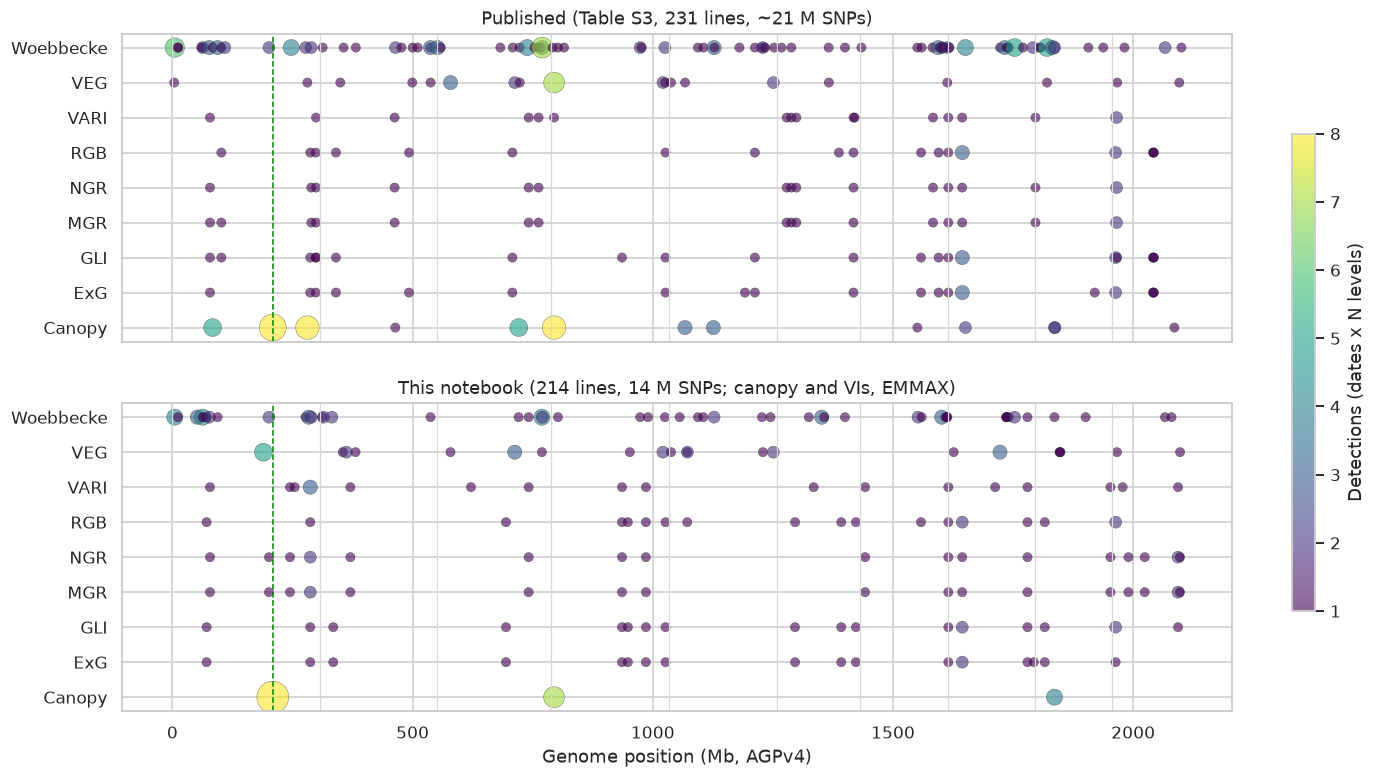

In [58]:
rloci["gpos"] = rloci.chrom.map(offset) + (rloci.start + rloci.end) / 2  # genome coordinate
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)         # published vs real, Figure 5A style
for ax, (tab, title) in zip(axes, [(loci, "Published (Table S3, 231 lines, ~21 M SNPs)"),
                                   (rloci, "This notebook (214 lines, 14 M SNPs; canopy and VIs, EMMAX)")]):
    for i, tr in enumerate(TR9):                                     # one track per trait
        s = tab[tab.trait == tr]
        ax.scatter(s.gpos / 1e6, np.full(len(s), i), s=12 + 25 * s.n_detections, c=s.n_detections,
                   cmap="viridis", vmin=1, vmax=8, alpha=0.6, edgecolor="k", lw=0.3)
    for c, o in offset.items():                                      # chromosome boundaries
        ax.axvline(o / 1e6, color="0.85", lw=0.8)
    ax.axvline((offset[1] + 209e6) / 1e6, color="green", ls="--", lw=1)  # HCF244 locus
    ax.set_yticks(range(len(TR9))); ax.set_yticklabels(TR9); ax.set_title(title)
axes[1].set_xlabel("Genome position (Mb, AGPv4)")
plt.colorbar(axes[1].collections[0], ax=axes, label="Detections (dates x N levels)", fraction=0.02)
plt.savefig(OUT / "figures/gwas_real_vs_published_loci.png"); plt.show()

**What the real genotypes show.**

* **The headline locus replicates exactly.** The chromosome 1 canopy-coverage locus is called in 18 of the 24
  GEMMA scans (9 dates, both N levels; best p = 8.0 × 10⁻¹⁰), and its lead SNP in the −N Aug 12 scan, the scan shown in
  Figure 5B of the paper, is the same SNP the paper reports, 209,091,350, next to *Zm00001d031997* (HCF244).
  A second canopy locus, chromosome 4 near 7.3 Mb, also replicates on 6 dates under both N levels.
* **Inflation is controlled.** λ_GC is 1.02 to 1.06 in GEMMA and 0.91 to 1.04 across all 216 EMMAX scans: kinship
  plus 3 PCs handle the structure of the panel.
* **Fewer, but the strongest, signals.** We call 38 canopy regions (11 loci) against the paper's 55 (13 loci) and
  recover 5 of the 13 published canopy loci, including 2 of the 7 found on three or more dates. With 214 instead of
  231 lines and 14 instead of 21 million SNPs, the weaker, single-date peaks are the first to drop below the
  threshold. Recurrence across dates remains the best guide to which signals are real.
* **EMMAX agrees with GEMMA.** On the canopy scans, −log10 p of the association tail correlates at r = 0.96 (median)
  between the two engines, and the same loci are called; EMMAX is slightly conservative (28 vs 38 region calls)
  because it fixes the variance ratio instead of re-estimating it per SNP.
* **VIs are not eight independent traits.** MGRVI is a monotonic transform of NGRDI and gives identical hits; ExG,
  GLI and RGBVI correlate above 0.99 across lines. The VIs collapse into about four signals (ExG/GLI/RGBVI,
  NGRDI/MGRVI/VARI, VEG, Woebbecke), so counting regions per VI overstates the evidence. Woebbecke, the most
  heritable index (SNP h² ≈ 0.85), gives the most regions (77; paper 144) and the most recurrent ones, and 8 of its
  16 recurrent published loci are recovered.

## Genomic prediction with real genotypes

GWAS finds a few large-effect loci; most of the genetic variance of canopy coverage and greenness is spread over
many small effects. Genomic prediction uses all markers at once. With GBLUP the genetic values of untested lines are
predicted from their genomic relationships to the tested lines,

û_test = K_test,train (K_train + δ I)⁻¹ (y_train − μ),  δ = σ²_e / σ²_g estimated by REML,

using the real kinship matrix of the 214 lines (GEMMA centred relatedness from all 14 million SNPs). We ask four
questions:

* **How accurate is it?** Repeated 5-fold cross-validation for canopy coverage and the 8 VIs on every date and N level.
  Accuracy is the correlation between predicted and observed genotype means; its ceiling is roughly √h².
* **Does it work for ground truth?** Leaf N, leaf area and 20-kernel weight (genotype means per N level).
* **Can +N data predict −N performance?** Train on genotype means under +N, test on held-out lines under −N.
* **Does it transfer across genetic groups?** Leave one PC-defined subpopulation out.

In [59]:
Kr = np.loadtxt(RES_G / "kinship_cXX.txt")                           # real centred kinship, 214 x 214
kid = (RES_G / "kinship_ids.txt").read_text().split()                # VCF sample ids in kinship order
idm = idmap.dropna()                                                 # matched lines only
gp_lines = pd.Series(kid).map(dict(zip(idm.vcf_id, idm.Genotype))).to_numpy()  # field genotype names
print(f"Kinship: {Kr.shape}, mean diagonal {Kr.diagonal().mean():.2f}, "
      f"mean off-diagonal {(Kr.sum() - np.trace(Kr)) / (Kr.size - len(Kr)):.3f}")

def gblup_fit_predict(y_tr, K_tr, K_te_tr):
    """GBLUP prediction of test lines from training lines; returns predictions and REML h2."""
    S, U = np.linalg.eigh(K_tr)                                      # eigen-decomposition of training kinship
    d = reml_delta(y_tr, np.ones((len(y_tr), 1)), np.clip(S, 1e-8, None), U)  # variance ratio by REML
    mu = y_tr.mean()                                                 # intercept
    return mu + K_te_tr @ np.linalg.solve(K_tr + d * np.eye(len(y_tr)), y_tr - mu), 1 / (1 + d)

def cv_accuracy(y, K, folds=5, reps=3):
    """Mean predictive correlation over repeated k-fold CV, plus genomic h2 and sample size."""
    ok = np.isfinite(y); y, K = y[ok], K[np.ix_(ok, ok)]             # lines with a phenotype
    rs = []                                                          # accuracy per repetition
    for rep in range(reps):                                          # repeat with new fold splits
        pred = np.full(len(y), np.nan)                               # out-of-fold predictions
        for tr, te in KFold(folds, shuffle=True, random_state=SEED + rep).split(y):
            pred[te] = gblup_fit_predict(y[tr], K[np.ix_(tr, tr)], K[np.ix_(te, tr)])[0]
        rs.append(stats.pearsonr(y, pred)[0])
    S, U = np.linalg.eigh(K)                                         # full-data REML for h2
    h2g = 1 / (1 + reml_delta(y, np.ones((len(y), 1)), np.clip(S, 1e-8, None), U))
    return np.mean(rs), h2g, len(y)

Kinship: (214, 214), mean diagonal 0.53, mean off-diagonal -0.002


In [60]:
img_traits = {"Canopy": None, **{v: v for v in VI8.values()}}        # canopy coverage + 8 normalised VIs
gp_rows = []                                                         # one row per trait x date x N level
for trt in TRT_COL:                                                  # +N and -N
    for d in DATES:                                                  # 12 flights
        cov_m = cg[(cg.Treatment == trt) & (cg.date == d)].groupby("Genotype.x")["Percent.Cover"].mean()
        vi_m = vin[(vin.Treatment == trt) & (vin.date == d)].groupby("Genotype.x")[list(VI8.values())].mean()
        for name, col in img_traits.items():                         # each image trait
            y = (cov_m if col is None else vi_m[col]).reindex(gp_lines).to_numpy()  # genotype means in K order
            r, h2g, n = cv_accuracy(y, Kr)                           # CV accuracy and genomic h2
            gp_rows.append({"trait": name, "Treatment": trt, "date": d, "r": r, "h2_g": h2g, "n": n})
gp = pd.DataFrame(gp_rows)                                           # long results table
gp["ceiling"] = np.sqrt(gp.h2_g)                                     # approximate upper bound of accuracy
gp.to_csv(OUT / "tables/genomic_prediction_real.csv", index=False)   # export
(gp.groupby("trait")[["r", "h2_g", "ceiling"]].mean()                # season means per trait
   .sort_values("r", ascending=False).round(3))

,r,h2_g,ceiling
trait,,,
Woebbecke,0.465,0.787,0.881
VEG,0.436,0.729,0.847
Canopy,0.366,0.642,0.782
ExG,0.249,0.556,0.731
RGBVI,0.236,0.541,0.719
GLI,0.227,0.529,0.710
NGRDI,0.189,0.465,0.658
MGRVI,0.188,0.461,0.655
VARI,0.165,0.426,0.621


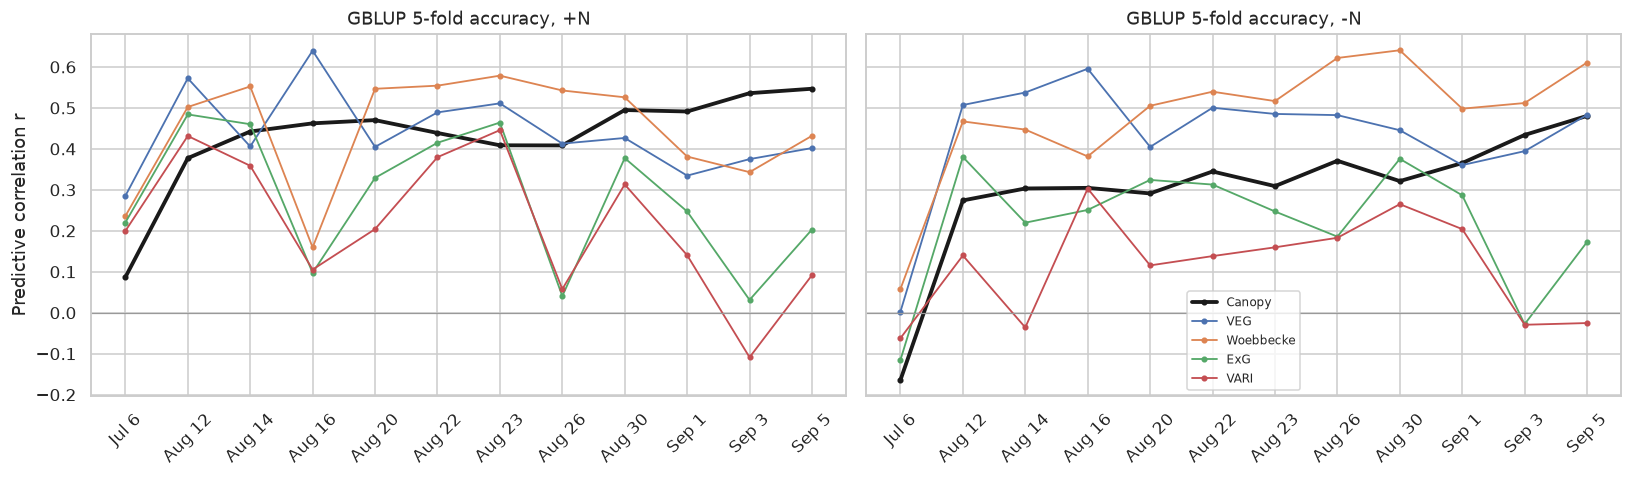

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)       # accuracy over the season
for ax, trt in zip(axes, TRT_COL):                                   # +N and -N panels
    piv = gp[gp.Treatment == trt].pivot(index="date", columns="trait", values="r").loc[DATES]
    for tr in ["Canopy", "VEG", "Woebbecke", "ExG", "VARI"]:         # representative traits
        ax.plot([LABEL[d] for d in DATES], piv[tr], marker="o", ms=3, lw=2.5 if tr == "Canopy" else 1.2,
                color="k" if tr == "Canopy" else None, label=tr)
    ax.axhline(0, color="0.6", lw=0.8); ax.tick_params(axis="x", rotation=45)
    ax.set_title(f"GBLUP 5-fold accuracy, {TRT_LAB[trt]}")
axes[0].set_ylabel("Predictive correlation r"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures/genomic_prediction_real.png"); plt.show()

In [62]:
field_gp = []                                                        # ground-truth traits
tr_tab = truth.merge(fb[["Row", "Genotype", "Treatment"]], on="Row") # plot traits with genotype and N level
for trt in TRT_COL:                                                  # per N level
    m = tr_tab[tr_tab.Treatment == trt].groupby("Genotype")[["Leaf N", "Leaf area", "20 kernel weight"]].mean()
    for c in m:                                                      # each ground-truth trait
        r, h2g, n = cv_accuracy(m[c].reindex(gp_lines).to_numpy(), Kr)
        field_gp.append({"trait": c, "N level": TRT_LAB[trt], "r": r, "h2_g": h2g, "ceiling": np.sqrt(h2g), "n": n})
pd.DataFrame(field_gp).round(3)

,trait,N level,r,h2_g,ceiling,n
0,Leaf N,+N,0.246,0.666,0.816,203
1,Leaf area,+N,0.464,0.876,0.936,204
2,20 kernel weight,+N,0.358,0.780,0.883,158
3,Leaf N,-N,0.402,0.613,0.783,194
4,Leaf area,-N,0.411,0.876,0.936,194
5,20 kernel weight,-N,0.379,0.849,0.921,131


In [63]:
cross = []                                                           # +N training, -N testing
for d in DATES[1:]:                                                  # two-replicate flights
    pn = cg[(cg.Treatment == "Nitrogen") & (cg.date == d)].groupby("Genotype.x")["Percent.Cover"].mean()
    mn = cg[(cg.Treatment == "No Nitrogen") & (cg.date == d)].groupby("Genotype.x")["Percent.Cover"].mean()
    pn, mn = pn.reindex(gp_lines).to_numpy(), mn.reindex(gp_lines).to_numpy()  # kinship order
    ok = np.isfinite(pn) & np.isfinite(mn)                           # lines observed in both
    pk, mk, Kk = pn[ok], mn[ok], Kr[np.ix_(ok, ok)]
    same, other = np.full(ok.sum(), np.nan), np.full(ok.sum(), np.nan)
    for trn, te in KFold(5, shuffle=True, random_state=SEED).split(mk):  # same held-out lines for both
        same[te] = gblup_fit_predict(mk[trn], Kk[np.ix_(trn, trn)], Kk[np.ix_(te, trn)])[0]   # -N -> -N
        other[te] = gblup_fit_predict(pk[trn], Kk[np.ix_(trn, trn)], Kk[np.ix_(te, trn)])[0]  # +N -> -N
    cross.append({"date": LABEL[d], "-N from -N": stats.pearsonr(mk, same)[0],
                  "-N from +N": stats.pearsonr(mk, other)[0], "phenotypic r(+N, -N)": stats.pearsonr(pk, mk)[0]})
pd.DataFrame(cross).set_index("date").round(3)

,-N from -N,-N from +N,"phenotypic r(+N, -N)"
date,,,
Aug 12,0.264,0.273,0.880
Aug 14,0.286,0.334,0.858
Aug 16,0.291,0.323,0.863
Aug 20,0.268,0.315,0.857
Aug 22,0.321,0.332,0.865
Aug 23,0.304,0.309,0.856
Aug 26,0.375,0.357,0.855
Aug 30,0.320,0.355,0.824
Sep 1,0.360,0.385,0.854


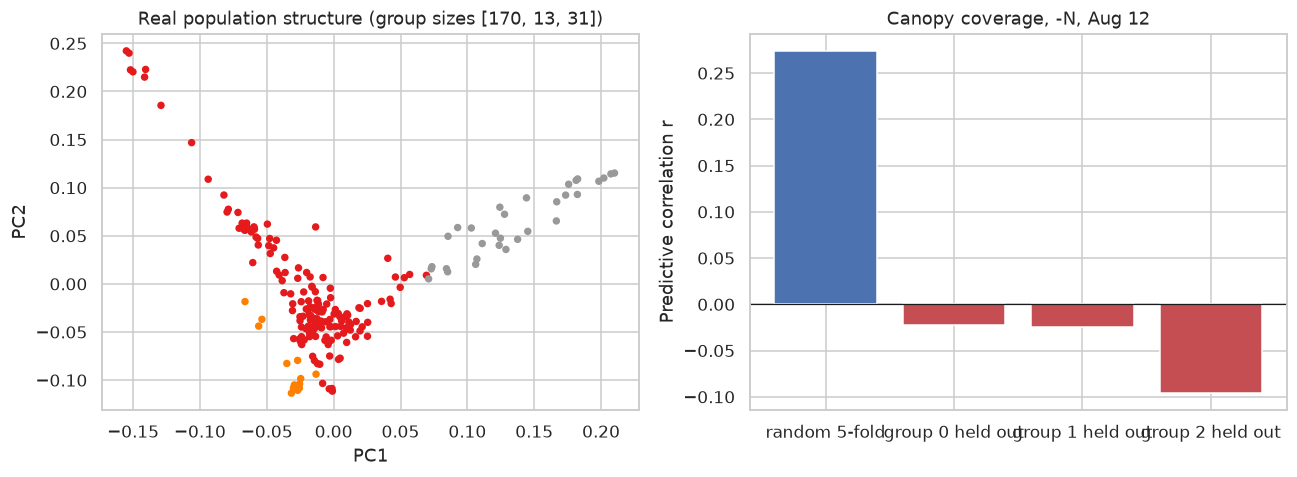

In [64]:
pcs_r = pd.read_csv(RES_G / "pca.eigenvec", sep="\t").set_index("IID").loc[kid, ["PC1", "PC2", "PC3"]]  # real PCs
from sklearn.cluster import KMeans                                   # group lines by population structure
grp = KMeans(3, n_init=10, random_state=SEED).fit_predict(pcs_r)     # three PC-defined groups
y = cg[(cg.Treatment == "No Nitrogen") & (cg.date == "Aug12")].groupby("Genotype.x")["Percent.Cover"].mean()
y = y.reindex(gp_lines).to_numpy(); ok = np.isfinite(y)              # -N Aug 12 canopy coverage
yk, Kk, gk = y[ok], Kr[np.ix_(ok, ok)], grp[ok]
lopo, rand = np.full(ok.sum(), np.nan), cv_accuracy(y, Kr)[0]        # leave-one-group-out vs random CV
for g in range(3):                                                   # hold out each group in turn
    te, trn = np.where(gk == g)[0], np.where(gk != g)[0]
    lopo[te] = gblup_fit_predict(yk[trn], Kk[np.ix_(trn, trn)], Kk[np.ix_(te, trn)])[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))                      # structure and accuracy
ax[0].scatter(pcs_r.PC1, pcs_r.PC2, c=grp, cmap="Set1", s=15)        # PC map of the 214 lines
ax[0].set(xlabel="PC1", ylabel="PC2", title=f"Real population structure (group sizes {np.bincount(grp).tolist()})")
acc_g = [stats.pearsonr(yk[gk == g], lopo[gk == g])[0] for g in range(3)]  # accuracy within each held-out group
ax[1].bar(["random 5-fold"] + [f"group {g} held out" for g in range(3)], [rand] + acc_g, color=["C0", "C3", "C3", "C3"])
ax[1].axhline(0, color="k", lw=0.8); ax[1].set(ylabel="Predictive correlation r",
                                                 title="Canopy coverage, -N, Aug 12")
plt.tight_layout(); plt.show()

In [65]:
gm_tr = gp.groupby("trait")[["r", "ceiling"]].mean()                 # season means per trait
assert (gm_tr.r > 0).all() and (gm_tr.r < gm_tr.ceiling).all()      # [CHECK] positive, below the sqrt(h2) ceiling

**What genomic prediction shows.**

* **Accuracy follows heritability.** Over the season, GBLUP predicts Woebbecke (r = 0.47), VEG (0.44) and canopy
  coverage (0.37) best, and VARI and NGRDI worst (about 0.17 to 0.19), the same order as their genomic h². All lie well
  below the √h² ceiling, as expected with about 170 training lines per fold.
* **Ground truth is predictable too.** Leaf area (r ≈ 0.41 to 0.46), 20-kernel weight (≈ 0.37) and leaf N
  (0.25 under +N, 0.40 under −N) can be predicted from markers alone, which is the basis of genomic selection for N-use
  traits.
* **+N data predict −N performance.** Training on +N genotype means predicts held-out lines under −N as well as
  training on −N itself (for example 0.27 vs 0.26 on Aug 12, 0.48 vs 0.49 on Sept 5), because canopy coverage under the
  two N levels is strongly correlated across lines (r ≈ 0.85). For this panel, genotype × N interaction is small
  relative to genetic main effects.
* **Prediction does not transfer across genetic groups.** Holding out a whole PC-defined subpopulation drops the
  accuracy to about zero, against 0.27 with random folds. Random cross-validation measures prediction for
  relatives of the training set; a breeding program predicting unrelated germplasm should expect much less.

## Phenomic prediction of leaf nitrogen

Back to real data. Single VI-date correlations reach R = 0.73 for leaf N. Can all eight VIs on all 12 dates
together predict leaf N better, and does the model generalise to *unseen genotypes*? We compare ridge regression
and a random forest under two cross-validation schemes:

* **random 5-fold** over plots, where the same genotype can sit in training (other rep) and test;
* **grouped 5-fold by genotype**, which mimics predicting new lines and is the honest scheme for breeding.

In [66]:
wide = (vin.pivot_table(index="Row", columns="date", values=list(VI8.values()))  # VI x date features per plot
           .dropna(axis=1, thresh=0.95 * vin.Row.nunique()))         # drop sparse columns
wide.columns = [f"{v}_{d}" for v, d in wide.columns]                 # flat names
data = (wide.join(truth.set_index("Row")["Leaf N"], how="inner")     # attach leaf N
            .join(fb.set_index("Row")[["Genotype", "Treatment"]]).dropna())  # attach groups
X, y_n, groups = data[wide.columns].to_numpy(), data["Leaf N"].to_numpy(), data.Genotype.to_numpy()
models = {"Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))),  # linear
          "Random forest": RandomForestRegressor(400, min_samples_leaf=3, random_state=SEED, n_jobs=-1)}
schemes = {"random 5-fold": KFold(5, shuffle=True, random_state=SEED), "by genotype": GroupKFold(5)}
pp = []                                                              # results
for mname, mdl in models.items():                                    # each model
    for sname, cv in schemes.items():                                # each CV scheme
        pr = cross_val_predict(mdl, X, y_n, cv=cv, groups=groups)    # out-of-fold predictions
        pp.append({"model": mname, "cv": sname, "r": stats.pearsonr(y_n, pr)[0],
                   "RMSE (%N)": np.sqrt(np.mean((y_n - pr) ** 2)), "R2": 1 - np.sum((y_n - pr) ** 2) / np.sum((y_n - y_n.mean()) ** 2)})
pp = pd.DataFrame(pp)                                                # table
print(f"{len(y_n)} plots with leaf N, {X.shape[1]} VI-date predictors; best single VI-date |r| = "
      f"{cors[cors.trait == 'Leaf N'].r.abs().max():.2f}")
pp.round(3)

498 plots with leaf N, 88 VI-date predictors; best single VI-date |r| = 0.73


,model,cv,r,RMSE (%N),R2
0,Ridge,random 5-fold,0.815,0.320,0.664
1,Ridge,by genotype,0.809,0.325,0.655
2,Random forest,random 5-fold,0.818,0.318,0.669
3,Random forest,by genotype,0.821,0.315,0.674


Combining all VIs and dates (r ≈ 0.82) beats the best single VI-date correlation (0.73), and grouping folds by
genotype costs almost nothing here, because most of the signal is the N treatment and canopy greenness rather than
genotype identity. With a trait dominated by genotype, grouped folds would be clearly less optimistic; always report
the scheme that matches the deployment question.

## Export, summary and exercises

In [67]:
exports = {"canopy_n_response_genotypes.csv": geno_test, "canopy_n_response_checks.csv": check_test,
           "vi_n_effect_checks.csv": vi_trt, "season_traits.csv": season,
           "gwas_recurrent_loci.csv": recurrent, "phenomic_prediction.csv": pp,
           "vi_normalised_plot_table.csv": vin.drop(columns=["Filename", "file"])}  # main results
for name, df in exports.items():                                     # write each table
    df.to_csv(OUT / "tables" / name, index=False)
manifest = sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file())  # everything produced
(OUT / "manifest.txt").write_text("\n".join(manifest))              # artefact list
print("\n".join(manifest))

figures/fig2_canopy_coverage.png
figures/fig3a_correlations.png
figures/fig3bcd_scatter.png
figures/fig5a_gwas_loci.png
figures/genomic_prediction_real.png
figures/gwas_real_chr1_zoom.png
figures/gwas_real_manhattan_aug12.png
figures/gwas_real_overview.png
figures/gwas_real_vs_published_loci.png
figures/gwas_simulated.png
figures/heritability.png
figures/light_saturation.png
figures/pixel_masks.png
figures/season_curves.png
figures/vi_checks_by_date.png
manifest.txt
tables/canopy_n_response_checks.csv
tables/canopy_n_response_genotypes.csv
tables/genomic_prediction_metrics.json
tables/genomic_prediction_real.csv
tables/gwas_real_canopy_loci.csv
tables/gwas_real_loci_all_traits.csv
tables/gwas_recurrent_loci.csv
tables/gwas_simulated.csv
tables/heritability.csv
tables/phenomic_prediction.csv
tables/provenance.json
tables/season_traits.csv
tables/vi_n_effect_checks.csv
tables/vi_normalised_plot_table.csv
tables/vi_trait_correlations.csv


### Summary

| Paper result | This notebook |
|---|---|
| ExG 131 chosen as the foliage filter | ExG 131 gives the largest +N/−N separation on the checks |
| Canopy coverage +N > −N, ratio 1.24 on July 6, fading by Sept 5 | Reproduced exactly at genotype level (paired t-tests match the published table) |
| 17 genotypes with ratio > 1.5 | 17 (season-mean ratio) |
| VIs depend on light value and saturation; normalise by both | Reproduced; normalised VIs separate +N from −N |
| VEG vs leaf N R = 0.73, Woebbecke vs leaf area R = −0.52, VARI vs 20-kernel weight R = 0.40 (Aug 22) | Reproduced |
| 29 regions detected at 3+ time points; Chr1 208.8 to 209.1 Mb canopy locus (HCF244) under both N levels | 28 with our merge rule; Chr1 locus on 8 dates under both N levels |
| GEMMA GWAS on HapMap3: Chr1 canopy locus, lead SNP 209,091,350 (−N Aug 12) | Rerun on real genotypes: same lead SNP, 9 dates, both N levels, p = 8.0 × 10⁻¹⁰; Chr4 locus also replicated; 5 of 13 published canopy loci recovered |

Added beyond the paper: season traits from the time series, heritability of every image trait by date (canopy
coverage is the most heritable), a fast EMMAX scan of all 216 image traits validated against GEMMA, genomic
prediction of image and field traits from real genotypes (including +N to −N transfer and across-group
prediction), and phenomic prediction of leaf N with honest cross-validation.

### Interpretation and limitations

* RGB VIs are proxies of greenness, not chlorophyll or N measurements; they inherit camera exposure, white balance
  and time-of-day effects. Fix camera settings, fly at the same time of day and keep a reference panel in view.
* Treatment is confounded with quadrant; the hybrid checks help but cannot remove soil differences between quadrants.
* Reference (nadir) replicates reduce viewing-angle noise; off-nadir copies dilute treatment effects.
* Twelve flights with a 37-day gap cannot resolve early growth; curve parameters need denser sampling.
* With 214 genotyped lines GWAS detects only larger-effect loci; recurrence across dates is evidence, not proof.
  Candidate genes such as *Zm00001d031997* need validation (mutants, expression, fine-mapping).
* The HapMap3 282-panel calls are low depth (about 7x) and not imputed; the call-rate filter removes a third of the
  SNPs, and 19 field lines have no sequenced sample. The simulated section teaches methods only.

### Exercises

1. **[EXERCISE] Filter sensitivity.** Repeat the canopy N-response test with the Otsu post filter. Which dates lose
   significance?
2. **[EXERCISE] Threshold sweep.** On the raw frame, vary the fixed ExG threshold from 120 to 145 and plot canopy
   coverage. How sensitive is coverage near 131?
3. **[EXERCISE] Normalisation.** Recompute the Figure 3A correlations with raw (unnormalised) VIs. On which dates
   does normalisation help most?
4. **[EXERCISE] Within-treatment correlations.** Compute VEG vs leaf N separately for +N and −N on Aug 22. How much
   of R = 0.73 is due to the treatment?
5. **[EXERCISE] Season traits.** Which season trait (max, AUC, senescence rate) has the highest heritability?
   Adapt `heritability()` to the `season` table.
6. **[EXERCISE] Spatial model.** Replace range-within-quadrant with a 2D polynomial of `fcol` and `frange` per
   quadrant. Does H² of canopy coverage increase?
7. **[EXERCISE] GWAS power.** Rerun the simulation with H² = 0.3 and 0.8 and with 50 instead of 12 QTL. How many QTL
   are recovered?
8. **[EXERCISE] Covariates.** Run the MLM without PCs (kinship only) and with PCs only. Compare λ_GC.
9. **[EXERCISE] CV design.** Compare 5-fold GBLUP accuracy with leave-one-subpopulation-out prediction. Why is it
   lower?
10. **[EXERCISE] Reproducibility.** Execute the notebook from a clean kernel with
    `jupyter nbconvert --to notebook --execute` and compare the output tables.

### References

* Rodene, E., Xu, G., Palali Delen, S., Smith, C., Ge, Y., Schnable, J., Yang, J. (2021). A UAV-based
  high-throughput phenotyping approach to assess time-series nitrogen responses and identify trait-associated
  genetic components in maize. *bioRxiv* 2021.05.24.445447. Code and data: github.com/jyanglab/UAV-based_HTP.
* Woebbecke, D. M., Meyer, G. E., Von Bargen, K., Mortensen, D. A. (1995). Color indices for weed identification
  under various soil, residue, and lighting conditions. *Transactions of the ASAE* 38(1), 259-269.
* Meyer, G. E., Neto, J. C. (2008). Verification of color vegetation indices for automated crop imaging
  applications. *Computers and Electronics in Agriculture* 63, 282-293.
* Flint-Garcia, S. A., et al. (2005). Maize association population: a high-resolution platform for quantitative
  trait locus dissection. *The Plant Journal* 44(6), 1054-1064.
* Bukowski, R., et al. (2018). Construction of the third-generation *Zea mays* haplotype map. *GigaScience* 7(4).
* Zhou, X., Stephens, M. (2012). Genome-wide efficient mixed-model analysis for association studies. *Nature
  Genetics* 44, 821-824.
* Kang, H. M., et al. (2010). Variance component model to account for sample structure in genome-wide association
  studies (EMMAX). *Nature Genetics* 42, 348-354.
* VanRaden, P. M. (2008). Efficient methods to compute genomic predictions. *Journal of Dairy Science* 91,
  4414-4423.
* Endelman, J. B. (2011). Ridge regression and other kernels for genomic selection with R package rrBLUP. *The Plant
  Genome* 4, 250-255.
* Araus, J. L., Cairns, J. E. (2014). Field high-throughput phenotyping: the new crop breeding frontier. *Trends in
  Plant Science* 19(1), 52-61.